In [1]:
!pip install -q kagglehub tensorflow_hub transformers torch

In [2]:
import kagglehub
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import train_test_split, StratifiedKFold
import os
import time
import pickle
import pandas as pd
from collections import defaultdict

In [3]:
print("="*60)
print("STEP 1: DOWNLOADING DATASET")
print("="*60)

path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
print(f"Path to dataset files: {path}")

DATA_DIR = os.path.join(path, "Garbage classification", "Garbage classification")
class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
NUM_CLASSES = 6
IMG_SIZE = 224

print(f"\n Dataset downloaded to: {DATA_DIR}")

STEP 1: DOWNLOADING DATASET


100%|██████████| 82.0M/82.0M [00:00<00:00, 113MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/asdasdasasdas/garbage-classification/versions/2

 Dataset downloaded to: /root/.cache/kagglehub/datasets/asdasdasasdas/garbage-classification/versions/2/Garbage classification/Garbage classification


In [4]:
print("\n" + "="*60)
print("VERIFYING DATASET STRUCTURE")
print("="*60)

for class_name in class_names:
    class_dir = os.path.join(DATA_DIR, class_name)
    if os.path.exists(class_dir):
        num_imgs = len([f for f in os.listdir(class_dir) if f.endswith(('.jpg', '.jpeg', '.png'))])
        print(f"  {class_name}: {num_imgs} images")
    else:
        print(f"  {class_name}: NOT FOUND")


VERIFYING DATASET STRUCTURE
  cardboard: 403 images
  glass: 501 images
  metal: 410 images
  paper: 594 images
  plastic: 482 images
  trash: 137 images


In [5]:
print("\n" + "="*60)
print("LOADING ALL IMAGE PATHS")
print("="*60)

file_paths = []
labels = []

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    for img_file in os.listdir(class_dir):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_paths.append(os.path.join(class_name, img_file))
            labels.append(class_idx)

print(f"Total images: {len(file_paths)}")


LOADING ALL IMAGE PATHS
Total images: 2527


In [6]:
print("\n" + "="*60)
print("STEP 1: 80/20 STRATIFIED SPLIT")
print("="*60)

train_paths, test_paths, train_labels, test_labels = train_test_split(
    file_paths, labels, test_size=0.2, stratify=labels, random_state=42
)

print(f"Training pool (80%): {len(train_paths)} images")
print(f"Test pool (20%): {len(test_paths)} images - ISOLATED")

# Save test set for later
with open('test_set_isolated.pkl', 'wb') as f:
    pickle.dump({'paths': test_paths, 'labels': test_labels, 'class_names': class_names}, f)
print(" Test set saved to 'test_set_isolated.pkl' - DO NOT USE")

# Show distribution
def print_dist(paths, labels, name):
    unique, counts = np.unique(labels, return_counts=True)
    print(f"\n{name} distribution:")
    for idx, count in zip(unique, counts):
        print(f"  {class_names[idx]}: {count} ({count/len(labels)*100:.1f}%)")

print_dist(train_paths, train_labels, "Training pool")
print_dist(test_paths, test_labels, "Test pool (isolated)")


STEP 1: 80/20 STRATIFIED SPLIT
Training pool (80%): 2021 images
Test pool (20%): 506 images - ISOLATED
 Test set saved to 'test_set_isolated.pkl' - DO NOT USE

Training pool distribution:
  cardboard: 322 (15.9%)
  glass: 401 (19.8%)
  metal: 328 (16.2%)
  paper: 475 (23.5%)
  plastic: 385 (19.0%)
  trash: 110 (5.4%)

Test pool (isolated) distribution:
  cardboard: 81 (16.0%)
  glass: 100 (19.8%)
  metal: 82 (16.2%)
  paper: 119 (23.5%)
  plastic: 97 (19.2%)
  trash: 27 (5.3%)


In [7]:
print("\n" + "="*60)
print("STEP 2: PREPROCESSING FUNCTIONS")
print("="*60)

def preprocess_image(image_path, label):
    full_path = tf.strings.join([DATA_DIR, "/", image_path])
    image = tf.io.read_file(full_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment_cnn(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    return image, label

def create_cnn_dataset(paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_cnn, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(lambda x, y: (x, tf.one_hot(y, depth=NUM_CLASSES)))
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

def create_vit_dataset(paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_cnn, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(lambda x, y: (x, tf.cast(y, tf.int32)))
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

print(" Preprocessing functions ready")


STEP 2: PREPROCESSING FUNCTIONS
 Preprocessing functions ready


In [18]:
print("\n" + "="*60)
print("STEP 2: PREPROCESSING FUNCTIONS")
print("="*60)

def preprocess_image(image_path, label):
    full_path = tf.strings.join([DATA_DIR, "/", image_path])
    image = tf.io.read_file(full_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# ============================================
# MODERATE AUGMENTATION (applied to all classes)
# ============================================
def augment_moderate(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.rot90(image, tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32))
    image = tf.image.random_brightness(image, max_delta=0.15)
    image = tf.image.random_contrast(image, lower=0.85, upper=1.15)
    image = tf.image.random_saturation(image, lower=0.85, upper=1.15)

    scale = tf.random.uniform([], 0.9, 1.0)
    image = tf.image.central_crop(image, central_fraction=scale)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    return tf.clip_by_value(image, 0.0, 1.0), label

# ============================================
# CLASS-BALANCED OVERSAMPLING (for training only)
# ============================================
def create_balanced_dataset(paths, labels, batch_size, num_classes=NUM_CLASSES,
                             augment=False, target_weights=None):
    """
    Builds one repeating, shuffled sub-dataset per class and interleaves them
    according to target_weights (defaults to uniform across classes), so every
    batch sees a controlled class mix instead of the raw imbalanced ratio.
    """
    paths = np.array(paths)
    labels = np.array(labels)

    if target_weights is None:
        target_weights = [1.0 / num_classes] * num_classes

    class_datasets = []
    for c in range(num_classes):
        class_paths = paths[labels == c]
        class_labels = labels[labels == c]
        ds = tf.data.Dataset.from_tensor_slices((class_paths, class_labels))
        ds = ds.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.shuffle(buffer_size=max(len(class_paths), 1), reshuffle_each_iteration=True)
        ds = ds.repeat()  # allow oversampling of minority classes
        class_datasets.append(ds)

    dataset = tf.data.Dataset.sample_from_datasets(class_datasets, weights=target_weights, seed=42)

    if augment:
        dataset = dataset.map(augment_moderate, num_parallel_calls=tf.data.AUTOTUNE)

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

def create_cnn_dataset_balanced(paths, labels, batch_size, augment=False, target_weights=None, steps_per_epoch=None):
    dataset = create_balanced_dataset(paths, labels, batch_size, augment=augment, target_weights=target_weights)
    dataset = dataset.map(lambda x, y: (x, tf.one_hot(y, depth=NUM_CLASSES)))
    return dataset

def create_vit_dataset_balanced(paths, labels, batch_size, augment=False, target_weights=None, steps_per_epoch=None):
    dataset = create_balanced_dataset(paths, labels, batch_size, augment=augment, target_weights=target_weights)
    dataset = dataset.map(lambda x, y: (x, tf.cast(y, tf.int32)))
    return dataset

# ============================================
# PLAIN DATASET (true class distribution, no oversampling/repeat) — for validation/test
# ============================================
def create_cnn_dataset_plain(paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_moderate, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(lambda x, y: (x, tf.one_hot(y, depth=NUM_CLASSES)))
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

def create_vit_dataset_plain(paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_moderate, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(lambda x, y: (x, tf.cast(y, tf.int32)))
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

print("Preprocessing functions ready")


STEP 2: PREPROCESSING FUNCTIONS
Preprocessing functions ready


In [8]:
print("\n" + "="*60)
print("STEP 3: CNN MODEL BUILDERS")
print("="*60)

from tensorflow.keras import layers

def build_mobilenetv2(num_classes=6, learning_rate=1e-4, weight_decay=0.0001):
    base = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base.trainable = False

    model = tf.keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax',
                     kernel_regularizer=tf.keras.regularizers.l2(weight_decay))
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=weight_decay),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def build_resnet50v2(num_classes=6, learning_rate=1e-4, weight_decay=0.0001):
    base = tf.keras.applications.ResNet50V2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base.trainable = False

    model = tf.keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax',
                     kernel_regularizer=tf.keras.regularizers.l2(weight_decay))
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=weight_decay),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print("CNN model builders ready")


STEP 3: CNN MODEL BUILDERS
CNN model builders ready


In [9]:
print("\n" + "="*60)
print("STEP 4: LOADING ViT PRETRAINED WEIGHTS")
print("="*60)

from transformers import ViTModel
import torch

print("Loading pretrained weights from HuggingFace...")
pt_model = ViTModel.from_pretrained('google/vit-base-patch16-224')
pt_model.eval()
pt_weights = {name: param.detach().numpy() for name, param in pt_model.named_parameters()}
print(f"Loaded {len(pt_weights)} weight tensors")


STEP 4: LOADING ViT PRETRAINED WEIGHTS
Loading pretrained weights from HuggingFace...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded 200 weight tensors


In [10]:
print("\n" + "="*60)
print("STEP 5: ViT BUILDING BLOCKS")
print("="*60)

def mlp_block(x, hidden_dim, out_dim, name):
    x = keras.layers.Dense(hidden_dim, activation='gelu', name=f"{name}_fc1")(x)
    x = keras.layers.Dense(out_dim, name=f"{name}_fc2")(x)
    return x

def attention_block(x, num_heads, head_dim, embed_dim, name):
    q = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_q")(x)
    k = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_k")(x)
    v = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_v")(x)

    q = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_q_reshape")(q)
    k = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_k_reshape")(k)
    v = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_v_reshape")(v)

    q = keras.layers.Permute((2, 1, 3), name=f"{name}_q_perm")(q)
    k = keras.layers.Permute((2, 1, 3), name=f"{name}_k_perm")(k)
    v = keras.layers.Permute((2, 1, 3), name=f"{name}_v_perm")(v)

    scale = head_dim ** -0.5
    attn = keras.layers.Lambda(
        lambda qk: keras.ops.softmax(
            keras.ops.matmul(qk[0], keras.ops.transpose(qk[1], (0, 1, 3, 2))) * scale,
            axis=-1
        ),
        name=f"{name}_attn_scores"
    )([q, k])

    out = keras.layers.Lambda(
        lambda av: keras.ops.matmul(av[0], av[1]),
        name=f"{name}_attn_out"
    )([attn, v])

    out = keras.layers.Permute((2, 1, 3), name=f"{name}_out_perm")(out)
    out = keras.layers.Reshape((-1, embed_dim), name=f"{name}_out_reshape")(out)
    out = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_proj")(out)
    return out

def transformer_block(x, num_heads=12, embed_dim=768, mlp_dim=3072, name="block"):
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(x)
    y = attention_block(y, num_heads=num_heads, head_dim=embed_dim // num_heads,
                        embed_dim=embed_dim, name=f"{name}_attn")
    x = keras.layers.Add()([x, y])
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x)
    y = mlp_block(y, hidden_dim=mlp_dim, out_dim=embed_dim, name=f"{name}_mlp")
    x = keras.layers.Add()([x, y])
    return x

print("ViT building blocks ready")


STEP 5: ViT BUILDING BLOCKS
ViT building blocks ready


In [11]:
print("\n" + "="*60)
print("STEP 6: BUILDING ViT MODEL")
print("="*60)

def build_vit_model(num_classes=6, learning_rate=2e-5, weight_decay=0.01):
    num_patches = (IMG_SIZE // 16) ** 2
    seq_len = num_patches + 1
    embed_dim = 768
    num_heads = 12
    mlp_dim = 3072
    num_layers = 12

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="pixel_values")

    patches = keras.layers.Conv2D(
        filters=embed_dim, kernel_size=16, strides=16,
        padding='valid', use_bias=True, name="patch_embed_proj"
    )(inputs)
    patches = keras.layers.Reshape((num_patches, embed_dim), name="patch_embed_reshape")(patches)

    class CLSToken(keras.layers.Layer):
        def build(self, input_shape):
            self.cls = self.add_weight(
                name="cls", shape=(1, 1, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return keras.ops.broadcast_to(self.cls, (keras.ops.shape(x)[0], 1, embed_dim))

    cls_tokens = CLSToken(name="cls_token")(patches)
    x = keras.layers.Concatenate(axis=1, name="cls_concat")([cls_tokens, patches])

    class PosEmbed(keras.layers.Layer):
        def build(self, input_shape):
            self.pos = self.add_weight(
                name="pos", shape=(1, seq_len, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return x + self.pos

    x = PosEmbed(name="pos_embed")(x)

    for i in range(num_layers):
        x = transformer_block(x, num_heads=num_heads, embed_dim=embed_dim,
                               mlp_dim=mlp_dim, name=f"block_{i}")

    x = keras.layers.LayerNormalization(epsilon=1e-6, name="ln_final")(x)
    cls_out = keras.layers.Lambda(lambda t: t[:, 0, :], name="cls_extract")(x)

    z = keras.layers.Dense(256, activation='relu', name="head_dense")(cls_out)
    z = keras.layers.Dropout(0.3, name="head_dropout")(z)
    outputs = keras.layers.Dense(num_classes, name="head_out")(z)

    vit_model = keras.Model(inputs=inputs, outputs=outputs)

    # Transfer pretrained weights
    print("Transferring pretrained weights...")

    def get_pt(key):
        return pt_weights[key]

    vit_model.get_layer("patch_embed_proj").set_weights([
        np.transpose(get_pt("embeddings.patch_embeddings.projection.weight"), (2, 3, 1, 0)),
        get_pt("embeddings.patch_embeddings.projection.bias")
    ])
    vit_model.get_layer("cls_token").set_weights([
        get_pt("embeddings.cls_token").reshape(1, 1, 768)
    ])
    vit_model.get_layer("pos_embed").set_weights([
        get_pt("embeddings.position_embeddings").reshape(1, 197, 768)
    ])

    for i in range(12):
        p = f"layers.{i}"
        vit_model.get_layer(f"block_{i}_ln1").set_weights([
            get_pt(f"{p}.layernorm_before.weight"),
            get_pt(f"{p}.layernorm_before.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_q").set_weights([
            get_pt(f"{p}.attention.q_proj.weight").T,
            get_pt(f"{p}.attention.q_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_k").set_weights([
            get_pt(f"{p}.attention.k_proj.weight").T,
            get_pt(f"{p}.attention.k_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_v").set_weights([
            get_pt(f"{p}.attention.v_proj.weight").T,
            get_pt(f"{p}.attention.v_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_proj").set_weights([
            get_pt(f"{p}.attention.o_proj.weight").T,
            get_pt(f"{p}.attention.o_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_ln2").set_weights([
            get_pt(f"{p}.layernorm_after.weight"),
            get_pt(f"{p}.layernorm_after.bias")
        ])
        vit_model.get_layer(f"block_{i}_mlp_fc1").set_weights([
            get_pt(f"{p}.mlp.fc1.weight").T,
            get_pt(f"{p}.mlp.fc1.bias")
        ])
        vit_model.get_layer(f"block_{i}_mlp_fc2").set_weights([
            get_pt(f"{p}.mlp.fc2.weight").T,
            get_pt(f"{p}.mlp.fc2.bias")
        ])

    vit_model.get_layer("ln_final").set_weights([
        get_pt("layernorm.weight"),
        get_pt("layernorm.bias")
    ])
    print(" Pretrained weights transferred")

    # Freeze backbone
    backbone_layers = [l for l in vit_model.layers if not l.name.startswith("head_")]
    for layer in backbone_layers:
        layer.trainable = False

    vit_model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=weight_decay
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )

    trainable = sum([tf.size(v).numpy() for v in vit_model.trainable_variables])
    non_trainable = sum([tf.size(v).numpy() for v in vit_model.non_trainable_variables])
    print(f"Trainable:     {trainable:,}")
    print(f"Non-trainable: {non_trainable:,}")
    print(f"Total:         {trainable + non_trainable:,}")

    return vit_model

print("ViT model builder ready")


STEP 6: BUILDING ViT MODEL
ViT model builder ready


In [ ]:
print("\n" + "="*60)
print("STEP 7: CROSS-VALIDATION FUNCTION")
print("="*60)

def cross_validate_model(model_builder, model_name, train_paths, train_labels,
                          batch_size, is_vit=False, num_folds=5):

    from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

    skf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=42)

    fold_metrics = {
        'macro_f1': [], 'accuracy': [], 'precision': [], 'recall': [],
        'latency_ms': [], 'history': []
    }

    for fold, (train_idx, val_idx) in enumerate(skf.split(train_paths, train_labels)):
        print(f"\n{'='*50}")
        print(f"Fold {fold+1}/{num_folds} - {model_name}")
        print(f"{'='*50}")

        fold_train_paths = [train_paths[i] for i in train_idx]
        fold_train_labels = [train_labels[i] for i in train_idx]
        fold_val_paths = [train_paths[i] for i in val_idx]
        fold_val_labels = [train_labels[i] for i in val_idx]

        print(f"Train: {len(fold_train_paths)}, Val: {len(fold_val_paths)}")

        if is_vit:
            train_ds = create_vit_dataset(fold_train_paths, fold_train_labels, batch_size, augment=True)
            val_ds = create_vit_dataset(fold_val_paths, fold_val_labels, batch_size, augment=False)
        else:
            train_ds = create_cnn_dataset(fold_train_paths, fold_train_labels, batch_size, augment=True)
            val_ds = create_cnn_dataset(fold_val_paths, fold_val_labels, batch_size, augment=False)

        model = model_builder()

        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True, verbose=0
        )
        reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, verbose=0
        )

        def measure_latency(model, dataset, num_samples=100):
            latencies = []
            for images, _ in dataset.take(1):
                images = images[:min(num_samples, len(images))]
                for i in range(len(images)):
                    single_img = images[i:i+1]
                    start = time.perf_counter()
                    _ = model.predict(single_img, verbose=0)
                    latencies.append((time.perf_counter() - start) * 1000)
            return np.mean(latencies)

        history = model.fit(
            train_ds, validation_data=val_ds, epochs=20,
            callbacks=[early_stop, reduce_lr], verbose=1
        )

        y_true, y_pred = [], []
        for images, labels in val_ds:
            preds = model.predict(images, verbose=0)
            if is_vit:
                y_true.extend(labels.numpy())
                y_pred.extend(np.argmax(preds, axis=1))
            else:
                y_true.extend(np.argmax(labels.numpy(), axis=1))
                y_pred.extend(np.argmax(preds, axis=1))

        macro_f1 = f1_score(y_true, y_pred, average='macro')
        accuracy = accuracy_score(y_true, y_pred)
        precision = precision_score(y_true, y_pred, average='macro')
        recall = recall_score(y_true, y_pred, average='macro')
        latency = measure_latency(model, val_ds)

        fold_metrics['macro_f1'].append(macro_f1)
        fold_metrics['accuracy'].append(accuracy)
        fold_metrics['precision'].append(precision)
        fold_metrics['recall'].append(recall)
        fold_metrics['latency_ms'].append(latency)
        fold_metrics['history'].append(history)

        print(f"Fold {fold+1} - F1: {macro_f1:.4f}, Acc: {accuracy:.4f}")

    print(f"\n{'='*50}")
    print(f"{model_name} - 5-Fold CV Results")
    print(f"{'='*50}")
    print(f"Macro F1:  {np.mean(fold_metrics['macro_f1']):.4f} ± {np.std(fold_metrics['macro_f1']):.4f}")
    print(f"Accuracy:  {np.mean(fold_metrics['accuracy']):.4f} ± {np.std(fold_metrics['accuracy']):.4f}")
    print(f"Latency:   {np.mean(fold_metrics['latency_ms']):.2f} ± {np.std(fold_metrics['latency_ms']):.2f} ms")

    return fold_metrics

print("Cross-validation function ready")


STEP 7: CROSS-VALIDATION FUNCTION
Cross-validation function ready


In [ ]:
print("\n" + "="*60)
print("STEP 8: PHASE 1 - 5-FOLD CROSS-VALIDATION")
print("="*60)

# Configs
batch_size_mobilenet = 32
batch_size_resnet = 32
batch_size_vit = 16

# MobileNetV2
print("\n" + "="*60)
print("STARTING 5-FOLD CV: MobileNetV2")
print("="*60)
mobilenet_results = cross_validate_model(
    lambda: build_mobilenetv2(NUM_CLASSES), "MobileNetV2",
    train_paths, train_labels, batch_size_mobilenet, is_vit=False
)

# ResNet50V2
print("\n" + "="*60)
print("STARTING 5-FOLD CV: ResNet50V2")
print("="*60)
resnet_results = cross_validate_model(
    lambda: build_resnet50v2(NUM_CLASSES), "ResNet50V2",
    train_paths, train_labels, batch_size_resnet, is_vit=False
)

# ViT
print("\n" + "="*60)
print("STARTING 5-FOLD CV: ViT")
print("="*60)
vit_results = cross_validate_model(
    lambda: build_vit_model(NUM_CLASSES), "ViT",
    train_paths, train_labels, batch_size_vit, is_vit=True
)

print("\n Phase 1 Cross-Validation Complete!")


STEP 8: PHASE 1 - 5-FOLD CROSS-VALIDATION

STARTING 5-FOLD CV: MobileNetV2

Fold 1/5 - MobileNetV2
Train: 1616, Val: 405
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 85s 902ms/step - accuracy: 0.2252 - loss: 2.0764 - val_accuracy: 0.3383 - val_loss: 1.7236 - learning_rate: 1.0000e-04
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.3261 - loss: 1.7460 - val_accuracy: 0.4469 - val_loss: 1.4952 - learning_rate: 1.0000e-04
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.4270 - loss: 1.5272 - val_accuracy: 0.5185 - val_loss: 1.3292 - learning_rate: 1.0000e-04
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.4851 - loss: 1.3577 - val_accuracy: 0.5704 - val_loss: 1.2070 - learning_rate: 1.0000e-04
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.5111 - loss: 1.2587 - val_accuracy: 0.6049 - val_loss: 1.1144 - learning_rate: 1.0000e-04
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step -

In [ ]:
print("\n" + "="*60)
print("STEP 9: SAVING PHASE 1 RESULTS")
print("="*60)

results_df = pd.DataFrame({
    'Model': ['MobileNetV2', 'ResNet50V2', 'ViT'],
    'Macro F1 (mean±std)': [
        f"{np.mean(mobilenet_results['macro_f1']):.4f} ± {np.std(mobilenet_results['macro_f1']):.4f}",
        f"{np.mean(resnet_results['macro_f1']):.4f} ± {np.std(resnet_results['macro_f1']):.4f}",
        f"{np.mean(vit_results['macro_f1']):.4f} ± {np.std(vit_results['macro_f1']):.4f}"
    ],
    'Accuracy': [
        f"{np.mean(mobilenet_results['accuracy']):.4f}",
        f"{np.mean(resnet_results['accuracy']):.4f}",
        f"{np.mean(vit_results['accuracy']):.4f}"
    ],
    'Latency (ms)': [
        f"{np.mean(mobilenet_results['latency_ms']):.2f}",
        f"{np.mean(resnet_results['latency_ms']):.2f}",
        f"{np.mean(vit_results['latency_ms']):.2f}"
    ]
})

print(results_df.to_string(index=False))
results_df.to_csv('phase1_cv_results.csv', index=False)
print("\n Phase 1 results saved to 'phase1_cv_results.csv'")

# Save raw results
phase1_raw = {
    'mobilenet': {
        'macro_f1': mobilenet_results['macro_f1'],
        'accuracy': mobilenet_results['accuracy'],
        'precision': mobilenet_results['precision'],
        'recall': mobilenet_results['recall'],
        'latency_ms': mobilenet_results['latency_ms']
    },
    'resnet': {
        'macro_f1': resnet_results['macro_f1'],
        'accuracy': resnet_results['accuracy'],
        'precision': resnet_results['precision'],
        'recall': resnet_results['recall'],
        'latency_ms': resnet_results['latency_ms']
    },
    'vit': {
        'macro_f1': vit_results['macro_f1'],
        'accuracy': vit_results['accuracy'],
        'precision': vit_results['precision'],
        'recall': vit_results['recall'],
        'latency_ms': vit_results['latency_ms']
    }
}

with open('phase1_raw_results.pkl', 'wb') as f:
    pickle.dump(phase1_raw, f)
print(" Raw results saved to 'phase1_raw_results.pkl'")


STEP 9: SAVING PHASE 1 RESULTS
      Model Macro F1 (mean±std) Accuracy Latency (ms)
MobileNetV2     0.7296 ± 0.0077   0.7694       242.24
 ResNet50V2     0.7496 ± 0.0222   0.7867       160.85
        ViT     0.8130 ± 0.0147   0.8525       237.74

 Phase 1 results saved to 'phase1_cv_results.csv'
 Raw results saved to 'phase1_raw_results.pkl'


In [ ]:
print("\n" + "="*60)
print("STEP: CROSS-VALIDATION FOLD RESULTS")
print("="*60)

# Extract fold-by-fold Macro F1 results
mobilenet_folds = mobilenet_results['macro_f1']
resnet_folds = resnet_results['macro_f1']
vit_folds = vit_results['macro_f1']

# Create DataFrame
cv_fold_df = pd.DataFrame({
    'Fold': [1, 2, 3, 4, 5],
    'MobileNetV2': mobilenet_folds,
    'ResNet50V2': resnet_folds,
    'ViT': vit_folds
})

# Add mean and std rows
mean_row = pd.DataFrame({
    'Fold': ['Mean'],
    'MobileNetV2': [np.mean(mobilenet_folds)],
    'ResNet50V2': [np.mean(resnet_folds)],
    'ViT': [np.mean(vit_folds)]
})

std_row = pd.DataFrame({
    'Fold': ['Std Dev'],
    'MobileNetV2': [np.std(mobilenet_folds)],
    'ResNet50V2': [np.std(resnet_folds)],
    'ViT': [np.std(vit_folds)]
})

cv_fold_df = pd.concat([cv_fold_df, mean_row, std_row], ignore_index=True)

print("\n5-Fold Cross-Validation Results (Macro F1):")
print(cv_fold_df.to_string(index=False))

# Save to CSV
cv_fold_df.to_csv('cv_fold_results.csv', index=False)
print("\nResults saved to 'cv_fold_results.csv'")

# Additional statistics
print("\n" + "="*60)
print("CROSS-VALIDATION STATISTICS")
print("="*60)
print(f"MobileNetV2: Mean = {np.mean(mobilenet_folds):.4f}, Std = {np.std(mobilenet_folds):.4f}")
print(f"ResNet50V2:  Mean = {np.mean(resnet_folds):.4f}, Std = {np.std(resnet_folds):.4f}")
print(f"ViT:         Mean = {np.mean(vit_folds):.4f}, Std = {np.std(vit_folds):.4f}")


STEP: CROSS-VALIDATION FOLD RESULTS

5-Fold Cross-Validation Results (Macro F1):
   Fold  MobileNetV2  ResNet50V2      ViT
      1     0.739632    0.775080 0.831207
      2     0.725526    0.708904 0.788019
      3     0.736221    0.753760 0.820241
      4     0.718127    0.748489 0.806812
      5     0.728372    0.761715 0.818580
   Mean     0.729576    0.749590 0.812972
Std Dev     0.007671    0.022229 0.014679

Results saved to 'cv_fold_results.csv'

CROSS-VALIDATION STATISTICS
MobileNetV2: Mean = 0.7296, Std = 0.0077
ResNet50V2:  Mean = 0.7496, Std = 0.0222
ViT:         Mean = 0.8130, Std = 0.0147


In [12]:
print("\n" + "="*60)
print("STEP 10: CREATING 90/10 SPLIT FOR FINAL TRAINING")
print("="*60)

train_paths_final, val_paths_final, train_labels_final, val_labels_final = train_test_split(
    train_paths, train_labels,
    test_size=0.1,
    stratify=train_labels,
    random_state=42
)

print(f"Final Train (90% of 80% pool): {len(train_paths_final)} images")
print(f"Final Val (10% of 80% pool): {len(val_paths_final)} images")
print(f"Test Set (20% isolated): {len(test_paths)} images")

# Show distribution
print_dist(train_paths_final, train_labels_final, "Final Train")
print_dist(val_paths_final, val_labels_final, "Final Val")


STEP 10: CREATING 90/10 SPLIT FOR FINAL TRAINING
Final Train (90% of 80% pool): 1818 images
Final Val (10% of 80% pool): 203 images
Test Set (20% isolated): 506 images

Final Train distribution:
  cardboard: 290 (16.0%)
  glass: 361 (19.9%)
  metal: 295 (16.2%)
  paper: 427 (23.5%)
  plastic: 346 (19.0%)
  trash: 99 (5.4%)

Final Val distribution:
  cardboard: 32 (15.8%)
  glass: 40 (19.7%)
  metal: 33 (16.3%)
  paper: 48 (23.6%)
  plastic: 39 (19.2%)
  trash: 11 (5.4%)


In [19]:
print("\n" + "="*60)
print("PHASE 2: FINAL TRAINING - MobileNetV2 (Two-Stage)")
print("="*60)

import gc
gc.collect()
tf.keras.backend.clear_session()
print("Memory cleared")

MOBILENET_CONFIG = {
    'learning_rate': 1e-4,
    'batch_size': 32,
    'weight_decay': 0.0001,
    'unfreeze_ratio': 0.25  # Unfreeze last 25% of inverted residual blocks
}

print(f"Config: LR={MOBILENET_CONFIG['learning_rate']}, "
      f"Batch={MOBILENET_CONFIG['batch_size']}, WD={MOBILENET_CONFIG['weight_decay']}")

# Create datasets
train_ds_mobilenet = create_cnn_dataset_balanced(
    train_paths_final, train_labels_final,
    MOBILENET_CONFIG['batch_size'],
    augment=True
)

# Validation: TRUE class distribution, no oversampling, no infinite repeat
val_ds_mobilenet = create_cnn_dataset_plain(
    val_paths_final, val_labels_final,
    MOBILENET_CONFIG['batch_size'],
    augment=False
)

# Required because the balanced training dataset repeats infinitely
steps_per_epoch = len(train_paths_final) // MOBILENET_CONFIG['batch_size']
validation_steps = len(val_paths_final) // MOBILENET_CONFIG['batch_size']

print(f"steps_per_epoch={steps_per_epoch}, validation_steps={validation_steps}")

# Build model
mobilenet_final = build_mobilenetv2(
    num_classes=NUM_CLASSES,
    learning_rate=MOBILENET_CONFIG['learning_rate'],
    weight_decay=MOBILENET_CONFIG['weight_decay']
)

early_stop_mobilenet = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)
reduce_lr_mobilenet = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1
)
checkpoint_mobilenet = tf.keras.callbacks.ModelCheckpoint(
    'mobilenet_stage1_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

print("\n[Stage 1] Training Frozen Backbone...")
history_mobilenet_stage1 = mobilenet_final.fit(
    train_ds_mobilenet,
    validation_data=val_ds_mobilenet,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=30,
    callbacks=[early_stop_mobilenet, reduce_lr_mobilenet, checkpoint_mobilenet],
    verbose=1
)

mobilenet_final.save('mobilenet_stage1_model.keras')
print("MobileNetV2 Stage 1 model saved")

print("\n[Stage 2] Unfreezing last 25% of layers...")

# Find all trainable layers (convolutional blocks)
trainable_layers = []
for layer in mobilenet_final.layers:
    if hasattr(layer, 'layers'):  # For nested models like MobileNetV2
        for sub_layer in layer.layers:
            if hasattr(sub_layer, 'trainable') and sub_layer.trainable is False:
                if isinstance(sub_layer, tf.keras.layers.Conv2D) or 'block' in sub_layer.name.lower():
                    trainable_layers.append(sub_layer)
    elif hasattr(layer, 'trainable') and layer.trainable is False:
        if isinstance(layer, tf.keras.layers.Conv2D) or 'block' in layer.name.lower():
            trainable_layers.append(layer)

# Alternative: Use the base model directly
base_model = None
for layer in mobilenet_final.layers:
    if hasattr(layer, 'layers') and hasattr(layer, 'input') and hasattr(layer, 'output'):
        base_model = layer
        break

if base_model is not None:
    # Get all conv layers from the base model
    conv_layers = []
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.Conv2D):
            conv_layers.append(layer)
        elif hasattr(layer, 'layers'):
            for sub_layer in layer.layers:
                if isinstance(sub_layer, tf.keras.layers.Conv2D):
                    conv_layers.append(sub_layer)

    # Unfreeze last 25%
    num_to_unfreeze = int(len(conv_layers) * MOBILENET_CONFIG['unfreeze_ratio'])
    unfrozen_layers = conv_layers[-num_to_unfreeze:]

    print(f"Found {len(conv_layers)} convolutional layers")
    print(f"Unfreezing last {num_to_unfreeze} layers ({MOBILENET_CONFIG['unfreeze_ratio']*100:.0f}%)")

    for layer in unfrozen_layers:
        layer.trainable = True
        print(f"  Unfroze: {layer.name}")
else:
    print("Warning: Could not find base model. Unfreezing by name pattern.")
    # Fallback: unfreeze by name pattern
    for layer in mobilenet_final.layers:
        if hasattr(layer, 'layers'):
            for sub_layer in layer.layers:
                if 'block' in sub_layer.name.lower():
                    block_num = int(sub_layer.name.split('_')[-1]) if '_' in sub_layer.name else 0
                    if block_num >= 10:  # Last few blocks
                        sub_layer.trainable = True
                        print(f"  Unfroze: {sub_layer.name}")

# Recompile with lower learning rate
STAGE2_LR_MOBILENET = 1e-5
mobilenet_final.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=STAGE2_LR_MOBILENET,
        weight_decay=MOBILENET_CONFIG['weight_decay']
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Reset callbacks for Stage 2
early_stop_mobilenet2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True, verbose=1
)
reduce_lr_mobilenet2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1
)
checkpoint_mobilenet2 = tf.keras.callbacks.ModelCheckpoint(
    'mobilenet_stage2_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train Stage 2
history_mobilenet_stage2 = mobilenet_final.fit(
    train_ds_mobilenet,
    validation_data=val_ds_mobilenet,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=10,
    callbacks=[early_stop_mobilenet2, reduce_lr_mobilenet2, checkpoint_mobilenet2],
    verbose=1
)

mobilenet_final.save('mobilenet_final_model.keras')
print("MobileNetV2 final model (two-stage) saved")


PHASE 2: FINAL TRAINING - MobileNetV2 (Two-Stage)
Memory cleared
Config: LR=0.0001, Batch=32, WD=0.0001
steps_per_epoch=56, validation_steps=6

[Stage 1] Training Frozen Backbone...
Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.2190 - loss: 2.0196
Epoch 1: val_accuracy improved from None to 0.39062, saving model to mobilenet_stage1_best.keras

Epoch 1: finished saving model to mobilenet_stage1_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 24s 208ms/step - accuracy: 0.2545 - loss: 1.9279 - val_accuracy: 0.3906 - val_loss: 1.5627 - learning_rate: 1.0000e-04
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.3461 - loss: 1.6947
Epoch 2: val_accuracy improved from 0.39062 to 0.46875, saving model to mobilenet_stage1_best.keras

Epoch 2: finished saving model to mobilenet_stage1_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - accuracy: 0.3616 - loss: 1.6405 - val_accuracy: 0.4688 - val_loss: 1.3873 - learning_rate: 1.0000e-04
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━

In [20]:
print("\n" + "="*60)
print("PHASE 2: FINAL TRAINING - ResNet50V2 (Two-Stage)")
print("="*60)

import gc
gc.collect()
tf.keras.backend.clear_session()
print("Memory cleared")

RESNET_CONFIG = {
    'learning_rate': 1e-4,
    'batch_size': 32,
    'weight_decay': 0.0001,
    'unfreeze_ratio': 0.25  # Unfreeze last 25% of layers
}

print(f"Config: LR={RESNET_CONFIG['learning_rate']}, "
      f"Batch={RESNET_CONFIG['batch_size']}, WD={RESNET_CONFIG['weight_decay']}")

# Create datasets
train_ds_resnet = create_cnn_dataset_balanced(
    train_paths_final, train_labels_final,
    RESNET_CONFIG['batch_size'],
    augment=True
)

# Validation: TRUE class distribution, no oversampling, no infinite repeat
val_ds_resnet = create_cnn_dataset_plain(
    val_paths_final, val_labels_final,
    RESNET_CONFIG['batch_size'],
    augment=False
)

# Required because the balanced training dataset repeats infinitely
steps_per_epoch = len(train_paths_final) // RESNET_CONFIG['batch_size']
validation_steps = len(val_paths_final) // RESNET_CONFIG['batch_size']

print(f"steps_per_epoch={steps_per_epoch}, validation_steps={validation_steps}")

# Build model
resnet_final = build_resnet50v2(
    num_classes=NUM_CLASSES,
    learning_rate=RESNET_CONFIG['learning_rate'],
    weight_decay=RESNET_CONFIG['weight_decay']
)

early_stop_resnet = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)
reduce_lr_resnet = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1
)
checkpoint_resnet = tf.keras.callbacks.ModelCheckpoint(
    'resnet_stage1_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

print("\n[Stage 1] Training Frozen Backbone...")
history_resnet_stage1 = resnet_final.fit(
    train_ds_resnet,
    validation_data=val_ds_resnet,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=30,
    callbacks=[early_stop_resnet, reduce_lr_resnet, checkpoint_resnet],
    verbose=1
)

resnet_final.save('resnet_stage1_model.keras')
print("ResNet50V2 Stage 1 model saved")

print("\n[Stage 2] Unfreezing last 25% of layers...")

# Find the base model (ResNet50V2)
base_model = None
for layer in resnet_final.layers:
    if hasattr(layer, 'layers') and hasattr(layer, 'input') and hasattr(layer, 'output'):
        base_model = layer
        break

if base_model is not None:
    # Get all conv layers from the base model
    conv_layers = []
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.Conv2D):
            conv_layers.append(layer)
        elif hasattr(layer, 'layers'):
            for sub_layer in layer.layers:
                if isinstance(sub_layer, tf.keras.layers.Conv2D):
                    conv_layers.append(sub_layer)

    # Unfreeze last 25%
    num_to_unfreeze = int(len(conv_layers) * RESNET_CONFIG['unfreeze_ratio'])
    unfrozen_layers = conv_layers[-num_to_unfreeze:]

    print(f"Found {len(conv_layers)} convolutional layers")
    print(f"Unfreezing last {num_to_unfreeze} layers ({RESNET_CONFIG['unfreeze_ratio']*100:.0f}%)")

    for layer in unfrozen_layers:
        layer.trainable = True
        print(f"  Unfroze: {layer.name}")
else:
    print("Warning: Could not find base model. Unfreezing by name pattern.")
    # Fallback: unfreeze last conv5 blocks
    for layer in resnet_final.layers:
        if hasattr(layer, 'layers'):
            for sub_layer in layer.layers:
                if sub_layer.name.startswith('conv5_block'):
                    sub_layer.trainable = True
                    print(f"  Unfroze: {sub_layer.name}")

# Recompile with lower learning rate
STAGE2_LR_RESNET = 1e-5
resnet_final.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=STAGE2_LR_RESNET,
        weight_decay=RESNET_CONFIG['weight_decay']
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Reset callbacks for Stage 2
early_stop_resnet2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True, verbose=1
)
reduce_lr_resnet2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1
)
checkpoint_resnet2 = tf.keras.callbacks.ModelCheckpoint(
    'resnet_stage2_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train Stage 2
history_resnet_stage2 = resnet_final.fit(
    train_ds_resnet,
    validation_data=val_ds_resnet,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=10,
    callbacks=[early_stop_resnet2, reduce_lr_resnet2, checkpoint_resnet2],
    verbose=1
)

resnet_final.save('resnet_final_model.keras')
print("ResNet50V2 final model (two-stage) saved")


PHASE 2: FINAL TRAINING - ResNet50V2 (Two-Stage)
Memory cleared
Config: LR=0.0001, Batch=32, WD=0.0001
steps_per_epoch=56, validation_steps=6
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

[Stage 1] Training Frozen Backbone...
Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.1722 - loss: 2.3977
Epoch 1: val_accuracy improved from None to 0.28646, saving model to resnet_stage1_best.keras

Epoch 1: finished saving model to resnet_stage1_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 27s 192ms/step - accuracy: 0.2243 - loss: 2.1759 - val_accuracy: 0.2865 - val_loss: 1.6628 - learning_rate: 1.0000e-04
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.3264 - loss: 1.7387
Epoch 2: val_accuracy improved from 0.28646 to 0.40104, saving model to resnet_stage1_best.keras

Epoch 2: finished saving model to resnet_stage1_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 8s 136ms/step - accuracy: 0.3410 - loss: 1.7166 - val_accuracy: 0.4010 - val_loss: 1.3836 - learning_rate: 1.0000

In [21]:
print("\n" + "="*60)
print("PHASE 2: FINAL TRAINING - ViT (50% Unfreeze)")
print("="*60)

import gc
gc.collect()
tf.keras.backend.clear_session()
print("Memory cleared")

VIT_CONFIG = {
    'learning_rate': 2e-5,
    'batch_size': 16,
    'weight_decay': 0.01
}

print(f"Config: LR={VIT_CONFIG['learning_rate']}, "
      f"Batch={VIT_CONFIG['batch_size']}, WD={VIT_CONFIG['weight_decay']}")

# Create datasets
train_ds_vit = create_vit_dataset_balanced(
    train_paths_final, train_labels_final,
    VIT_CONFIG['batch_size'],
    augment=True
)

# Validation: TRUE class distribution, no oversampling, no infinite repeat
val_ds_vit = create_vit_dataset_plain(
    val_paths_final, val_labels_final,
    VIT_CONFIG['batch_size'],
    augment=False
)

# Required because the balanced training dataset repeats infinitely
steps_per_epoch = len(train_paths_final) // VIT_CONFIG['batch_size']
validation_steps = len(val_paths_final) // VIT_CONFIG['batch_size']

print(f"steps_per_epoch={steps_per_epoch}, validation_steps={validation_steps}")

# Build fresh model
vit_model_phase2 = build_vit_model(
    num_classes=NUM_CLASSES,
    learning_rate=VIT_CONFIG['learning_rate'],
    weight_decay=VIT_CONFIG['weight_decay']
)

early_stop_vit_stage1 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)
reduce_lr_vit_stage1 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1
)
checkpoint_vit_stage1 = tf.keras.callbacks.ModelCheckpoint(
    'vit_stage1_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Stage 1: Train Frozen Backbone
print("\n" + "-"*40)
print("STAGE 1: Training Frozen Backbone")
print("-"*40)

history_vit_stage1 = vit_model_phase2.fit(
    train_ds_vit,
    validation_data=val_ds_vit,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=30,
    callbacks=[early_stop_vit_stage1, reduce_lr_vit_stage1, checkpoint_vit_stage1],
    verbose=1
)

vit_model_phase2.save('vit_stage1_model.keras')
print("ViT Stage 1 model saved")

# Stage 2: Unfreeze 50%
print("\n" + "-"*40)
print("STAGE 2: Unfreezing Last 50% of Transformer Blocks")
print("-"*40)

transformer_blocks = []
for layer in vit_model_phase2.layers:
    if layer.name.startswith("block_"):
        transformer_blocks.append(layer)

num_blocks = len(transformer_blocks)
num_to_unfreeze = int(num_blocks * 0.5)
unfrozen_blocks = transformer_blocks[-num_to_unfreeze:]

print(f"Unfreezing last {num_to_unfreeze} blocks ({num_to_unfreeze/num_blocks*100:.0f}%)")

for block in unfrozen_blocks:
    block.trainable = True

# Recompile with lower LR
STAGE2_LR = 1e-5
vit_model_phase2.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=STAGE2_LR,
        weight_decay=0.01
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

early_stop_vit_stage2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True, verbose=1
)
reduce_lr_vit_stage2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1
)
checkpoint_vit_stage2 = tf.keras.callbacks.ModelCheckpoint(
    'vit_final_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train Stage 2
history_vit_stage2 = vit_model_phase2.fit(
    train_ds_vit,
    validation_data=val_ds_vit,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=10,
    callbacks=[early_stop_vit_stage2, reduce_lr_vit_stage2, checkpoint_vit_stage2],
    verbose=1
)

vit_model_phase2.save('vit_final_50percent.keras')
print("ViT final model (50% unfreeze) saved")


PHASE 2: FINAL TRAINING - ViT (50% Unfreeze)
Memory cleared
Config: LR=2e-05, Batch=16, WD=0.01
steps_per_epoch=113, validation_steps=12
Transferring pretrained weights...
 Pretrained weights transferred
Trainable:     198,406
Non-trainable: 85,798,658
Total:         85,997,064

----------------------------------------
STAGE 1: Training Frozen Backbone
----------------------------------------
Epoch 1/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - accuracy: 0.1687 - loss: 2.3343
Epoch 1: val_accuracy improved from None to 0.44271, saving model to vit_stage1_best.keras

Epoch 1: finished saving model to vit_stage1_best.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 96s 681ms/step - accuracy: 0.2085 - loss: 2.1048 - val_accuracy: 0.4427 - val_loss: 1.5243 - learning_rate: 2.0000e-05
Epoch 2/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.3648 - loss: 1.6134
Epoch 2: val_accuracy improved from 0.44271 to 0.61458, saving model to vit_stage1_best.keras

Epoch 2: finished saving model to vi

In [29]:
import zipfile
import os
import shutil

# The .keras file is a zip archive
keras_path = 'vit_final_50percent.keras'
extract_dir = 'vit_extracted'

# Step 1: Extract the .keras file
with zipfile.ZipFile(keras_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print(f"Extracted to: {extract_dir}")
print("Files:", os.listdir(extract_dir))

# Step 2: Find the .h5 weights file inside
weights_file = None
for root, dirs, files in os.walk(extract_dir):
    for file in files:
        if file.endswith('.h5'):
            weights_file = os.path.join(root, file)
            print(f"Found weights file: {weights_file}")
            break
    if weights_file:
        break

if weights_file:
    # Copy to a new location
    shutil.copy(weights_file, 'vit_weights_clean.h5')
    print("Weights saved as: vit_weights_clean.h5")

    # Download
    from google.colab import files
    files.download('vit_weights_clean.h5')
else:
    print("No .h5 file found")

Extracted to: vit_extracted
Files: ['model.weights.h5', 'metadata.json', 'config.json']
Found weights file: vit_extracted/model.weights.h5
Weights saved as: vit_weights_clean.h5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


STEP: PLOTTING ALL TRAINING CURVES

----------------------------------------
MobileNetV2 Training Curves
----------------------------------------


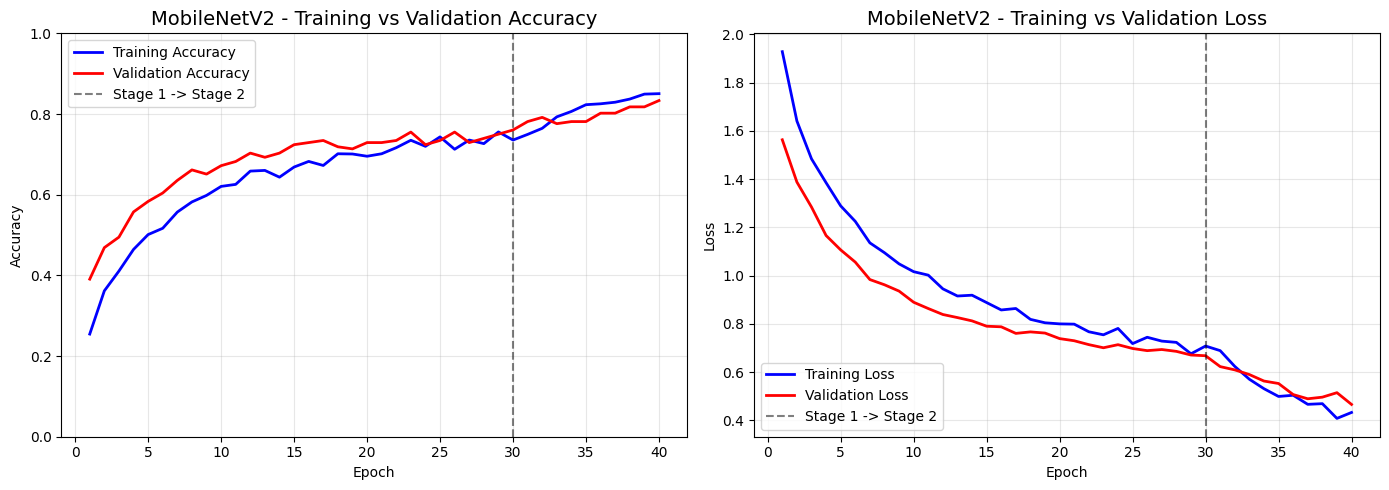

MobileNetV2 curves saved (two-stage)

----------------------------------------
ResNet50V2 Training Curves
----------------------------------------


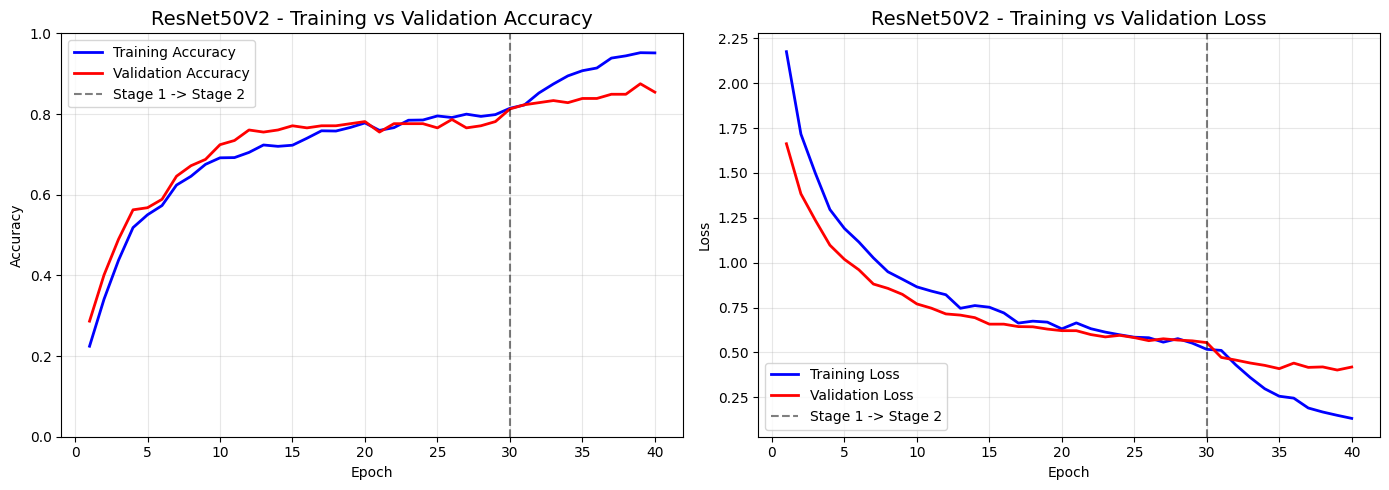

ResNet50V2 curves saved (two-stage)

----------------------------------------
ViT Training Curves
----------------------------------------


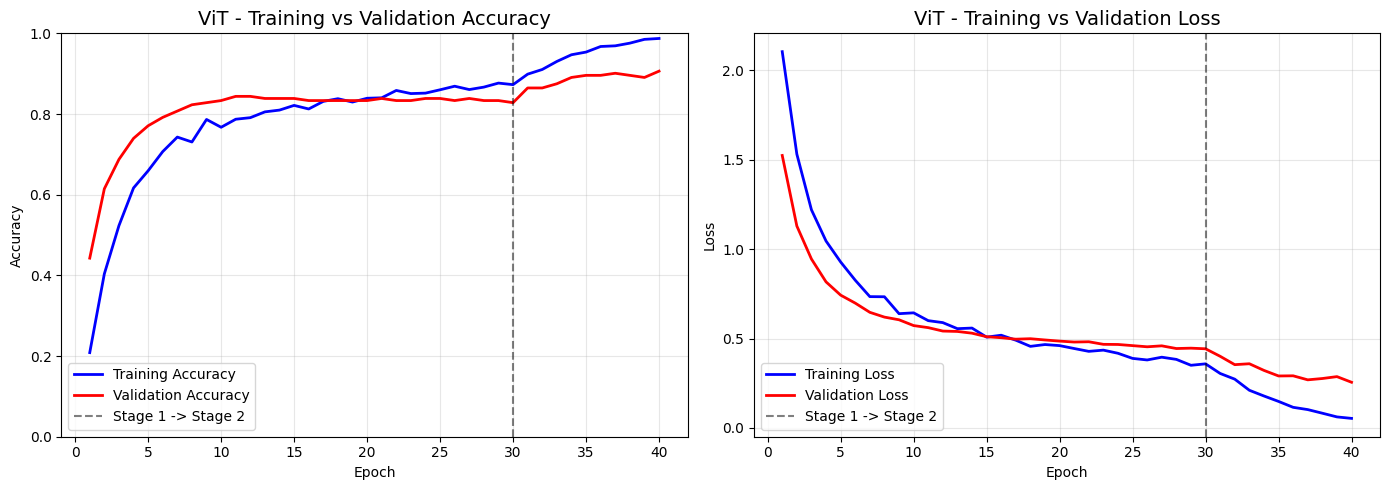

ViT curves saved (two-stage)

TRAINING CURVES SUMMARY

Files saved:
  - mobilenet_final_training_curves.png
  - resnet_final_training_curves.png
  - vit_final_training_curves.png

All available training curves plotted and saved!


In [24]:
print("\n" + "="*60)
print("STEP: PLOTTING ALL TRAINING CURVES")
print("="*60)

# ============================================
# 1. MobileNetV2 Training Curves
# ============================================
print("\n" + "-"*40)
print("MobileNetV2 Training Curves")
print("-"*40)

# Try two-stage first, then fallback to single-stage
if 'history_mobilenet_stage1' in locals() and 'history_mobilenet_stage2' in locals():
    # Two-stage available
    stage1_epochs = len(history_mobilenet_stage1.history['accuracy'])

    train_acc = history_mobilenet_stage1.history['accuracy'] + history_mobilenet_stage2.history['accuracy']
    val_acc = history_mobilenet_stage1.history['val_accuracy'] + history_mobilenet_stage2.history['val_accuracy']
    train_loss = history_mobilenet_stage1.history['loss'] + history_mobilenet_stage2.history['loss']
    val_loss = history_mobilenet_stage1.history['val_loss'] + history_mobilenet_stage2.history['val_loss']

    epochs_range = range(1, len(train_acc) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs_range, train_acc, 'b-', label='Training Accuracy', linewidth=2)
    axes[0].plot(epochs_range, val_acc, 'r-', label='Validation Accuracy', linewidth=2)
    axes[0].axvline(x=stage1_epochs, color='black', linestyle='--', alpha=0.5, label='Stage 1 -> Stage 2')
    axes[0].set_title('MobileNetV2 - Training vs Validation Accuracy', fontsize=14)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim([0, 1])

    axes[1].plot(epochs_range, train_loss, 'b-', label='Training Loss', linewidth=2)
    axes[1].plot(epochs_range, val_loss, 'r-', label='Validation Loss', linewidth=2)
    axes[1].axvline(x=stage1_epochs, color='black', linestyle='--', alpha=0.5, label='Stage 1 -> Stage 2')
    axes[1].set_title('MobileNetV2 - Training vs Validation Loss', fontsize=14)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('mobilenet_final_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("MobileNetV2 curves saved (two-stage)")

elif 'history_mobilenet_final' in locals():
    # Single-stage fallback
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history_mobilenet_final.history['accuracy'], 'b-', label='Training Accuracy', linewidth=2)
    axes[0].plot(history_mobilenet_final.history['val_accuracy'], 'r-', label='Validation Accuracy', linewidth=2)
    axes[0].set_title('MobileNetV2 - Training vs Validation Accuracy', fontsize=14)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim([0, 1])

    axes[1].plot(history_mobilenet_final.history['loss'], 'b-', label='Training Loss', linewidth=2)
    axes[1].plot(history_mobilenet_final.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    axes[1].set_title('MobileNetV2 - Training vs Validation Loss', fontsize=14)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('mobilenet_final_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("MobileNetV2 curves saved (single-stage)")

else:
    print("MobileNetV2 history not available. Please run training cells first.")

# ============================================
# 2. ResNet50V2 Training Curves
# ============================================
print("\n" + "-"*40)
print("ResNet50V2 Training Curves")
print("-"*40)

if 'history_resnet_stage1' in locals() and 'history_resnet_stage2' in locals():
    stage1_epochs = len(history_resnet_stage1.history['accuracy'])

    train_acc = history_resnet_stage1.history['accuracy'] + history_resnet_stage2.history['accuracy']
    val_acc = history_resnet_stage1.history['val_accuracy'] + history_resnet_stage2.history['val_accuracy']
    train_loss = history_resnet_stage1.history['loss'] + history_resnet_stage2.history['loss']
    val_loss = history_resnet_stage1.history['val_loss'] + history_resnet_stage2.history['val_loss']

    epochs_range = range(1, len(train_acc) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs_range, train_acc, 'b-', label='Training Accuracy', linewidth=2)
    axes[0].plot(epochs_range, val_acc, 'r-', label='Validation Accuracy', linewidth=2)
    axes[0].axvline(x=stage1_epochs, color='black', linestyle='--', alpha=0.5, label='Stage 1 -> Stage 2')
    axes[0].set_title('ResNet50V2 - Training vs Validation Accuracy', fontsize=14)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim([0, 1])

    axes[1].plot(epochs_range, train_loss, 'b-', label='Training Loss', linewidth=2)
    axes[1].plot(epochs_range, val_loss, 'r-', label='Validation Loss', linewidth=2)
    axes[1].axvline(x=stage1_epochs, color='black', linestyle='--', alpha=0.5, label='Stage 1 -> Stage 2')
    axes[1].set_title('ResNet50V2 - Training vs Validation Loss', fontsize=14)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('resnet_final_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("ResNet50V2 curves saved (two-stage)")

elif 'history_resnet_final' in locals():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history_resnet_final.history['accuracy'], 'b-', label='Training Accuracy', linewidth=2)
    axes[0].plot(history_resnet_final.history['val_accuracy'], 'r-', label='Validation Accuracy', linewidth=2)
    axes[0].set_title('ResNet50V2 - Training vs Validation Accuracy', fontsize=14)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim([0, 1])

    axes[1].plot(history_resnet_final.history['loss'], 'b-', label='Training Loss', linewidth=2)
    axes[1].plot(history_resnet_final.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    axes[1].set_title('ResNet50V2 - Training vs Validation Loss', fontsize=14)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('resnet_final_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("ResNet50V2 curves saved (single-stage)")

else:
    print("ResNet50V2 history not available. Please run training cells first.")

# ============================================
# 3. ViT Training Curves (Two Stages)
# ============================================
print("\n" + "-"*40)
print("ViT Training Curves")
print("-"*40)

if 'history_vit_stage1' in locals() and 'history_vit_stage2' in locals():
    stage1_epochs = len(history_vit_stage1.history['accuracy'])

    train_acc = history_vit_stage1.history['accuracy'] + history_vit_stage2.history['accuracy']
    val_acc = history_vit_stage1.history['val_accuracy'] + history_vit_stage2.history['val_accuracy']
    train_loss = history_vit_stage1.history['loss'] + history_vit_stage2.history['loss']
    val_loss = history_vit_stage1.history['val_loss'] + history_vit_stage2.history['val_loss']

    epochs_range = range(1, len(train_acc) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs_range, train_acc, 'b-', label='Training Accuracy', linewidth=2)
    axes[0].plot(epochs_range, val_acc, 'r-', label='Validation Accuracy', linewidth=2)
    axes[0].axvline(x=stage1_epochs, color='black', linestyle='--', alpha=0.5, label='Stage 1 -> Stage 2')
    axes[0].set_title('ViT - Training vs Validation Accuracy', fontsize=14)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim([0, 1])

    axes[1].plot(epochs_range, train_loss, 'b-', label='Training Loss', linewidth=2)
    axes[1].plot(epochs_range, val_loss, 'r-', label='Validation Loss', linewidth=2)
    axes[1].axvline(x=stage1_epochs, color='black', linestyle='--', alpha=0.5, label='Stage 1 -> Stage 2')
    axes[1].set_title('ViT - Training vs Validation Loss', fontsize=14)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('vit_final_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("ViT curves saved (two-stage)")

elif 'history_vit_final' in locals():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history_vit_final.history['accuracy'], 'b-', label='Training Accuracy', linewidth=2)
    axes[0].plot(history_vit_final.history['val_accuracy'], 'r-', label='Validation Accuracy', linewidth=2)
    axes[0].set_title('ViT - Training vs Validation Accuracy', fontsize=14)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim([0, 1])

    axes[1].plot(history_vit_final.history['loss'], 'b-', label='Training Loss', linewidth=2)
    axes[1].plot(history_vit_final.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    axes[1].set_title('ViT - Training vs Validation Loss', fontsize=14)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('vit_final_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("ViT curves saved (single-stage)")

else:
    print("ViT history not available. Please run training cells first.")

print("\n" + "="*60)
print("TRAINING CURVES SUMMARY")
print("="*60)

print("\nFiles saved:")
print("  - mobilenet_final_training_curves.png")
print("  - resnet_final_training_curves.png")
print("  - vit_final_training_curves.png")

print("\nAll available training curves plotted and saved!")

In [25]:
print("\n" + "="*60)
print("STEP 11: FINAL TEST EVALUATION - ALL MODELS")
print("="*60)

# Load test set
with open('test_set_isolated.pkl', 'rb') as f:
    test_data = pickle.load(f)

test_paths = test_data['paths']
test_labels = test_data['labels']

print(f"Test set: {len(test_paths)} images")

# Create test dataset (true class distribution, no oversampling, no infinite repeat)
test_ds_cnn = create_cnn_dataset_plain(test_paths, test_labels, batch_size=32, augment=False)
test_ds_vit = create_vit_dataset_plain(test_paths, test_labels, batch_size=16, augment=False)

def evaluate_on_test(model, model_name, test_ds, is_vit=False):
    print(f"\n{'='*60}")
    print(f"Evaluating {model_name} on Test Set")
    print('='*60)

    y_true, y_pred = [], []
    for images, labels in test_ds:
        preds = model.predict(images, verbose=0)
        if is_vit:
            y_true.extend(labels.numpy())
            y_pred.extend(np.argmax(preds, axis=1))
        else:
            y_true.extend(np.argmax(labels.numpy(), axis=1))
            y_pred.extend(np.argmax(preds, axis=1))

    print(classification_report(y_true, y_pred, target_names=class_names))

    macro_f1 = f1_score(y_true, y_pred, average='macro')
    accuracy = accuracy_score(y_true, y_pred)

    print(f"\n {model_name} - Test Results:")
    print(f"   Macro F1: {macro_f1:.4f}")
    print(f"   Accuracy: {accuracy:.4f}")

    return {'macro_f1': macro_f1, 'accuracy': accuracy, 'y_true': y_true, 'y_pred': y_pred}

# Evaluate all models
mobilenet_test = evaluate_on_test(mobilenet_final, "MobileNetV2", test_ds_cnn, is_vit=False)
resnet_test = evaluate_on_test(resnet_final, "ResNet50V2", test_ds_cnn, is_vit=False)
vit_test = evaluate_on_test(vit_model_phase2, "ViT (50% Unfreeze)", test_ds_vit, is_vit=True)

# Save results
with open('final_test_results.pkl', 'wb') as f:
    pickle.dump({
        'mobilenet': mobilenet_test,
        'resnet': resnet_test,
         'vit': vit_test
    }, f)
print("\n Final test results saved to 'final_test_results.pkl'")


STEP 11: FINAL TEST EVALUATION - ALL MODELS
Test set: 506 images

Evaluating MobileNetV2 on Test Set
              precision    recall  f1-score   support

   cardboard       0.94      0.89      0.91        81
       glass       0.85      0.81      0.83       100
       metal       0.84      0.83      0.83        82
       paper       0.90      0.92      0.91       119
     plastic       0.86      0.84      0.85        97
       trash       0.57      0.78      0.66        27

    accuracy                           0.86       506
   macro avg       0.83      0.84      0.83       506
weighted avg       0.86      0.86      0.86       506


 MobileNetV2 - Test Results:
   Macro F1: 0.8323
   Accuracy: 0.8557

Evaluating ResNet50V2 on Test Set
              precision    recall  f1-score   support

   cardboard       0.96      0.91      0.94        81
       glass       0.85      0.96      0.90       100
       metal       0.95      0.90      0.93        82
       paper       0.92      0.91

In [26]:
print("\n" + "="*60)
print("FINAL MODEL COMPARISON - TEST SET")
print("="*60)

comparison_df = pd.DataFrame({
    'Model': ['MobileNetV2', 'ResNet50V2', 'ViT (50% Unfreeze)'],
    'Macro F1': [
        f"{mobilenet_test['macro_f1']:.4f}",
        f"{resnet_test['macro_f1']:.4f}",
        f"{vit_test['macro_f1']:.4f}"
    ],
    'Accuracy': [
        f"{mobilenet_test['accuracy']:.4f}",
        f"{resnet_test['accuracy']:.4f}",
        f"{vit_test['accuracy']:.4f}"
    ]
})

print(comparison_df.to_string(index=False))
comparison_df.to_csv('final_comparison_results.csv', index=False)
print("\n Final comparison saved to 'final_comparison_results.csv'")


FINAL MODEL COMPARISON - TEST SET
             Model Macro F1 Accuracy
       MobileNetV2   0.8323   0.8557
        ResNet50V2   0.8517   0.8874
ViT (50% Unfreeze)   0.9145   0.9427

 Final comparison saved to 'final_comparison_results.csv'



CONFUSION MATRICES - ALL MODELS


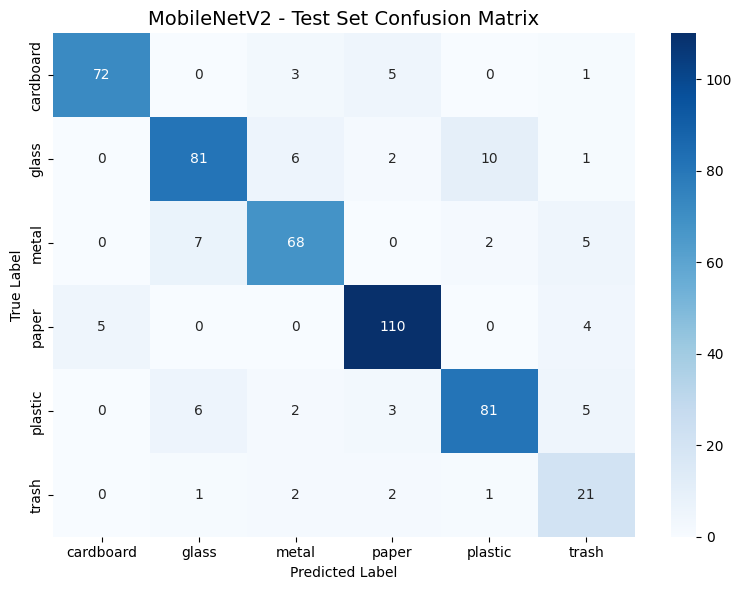


MobileNetV2 - Correct: 433/506 (85.57%)


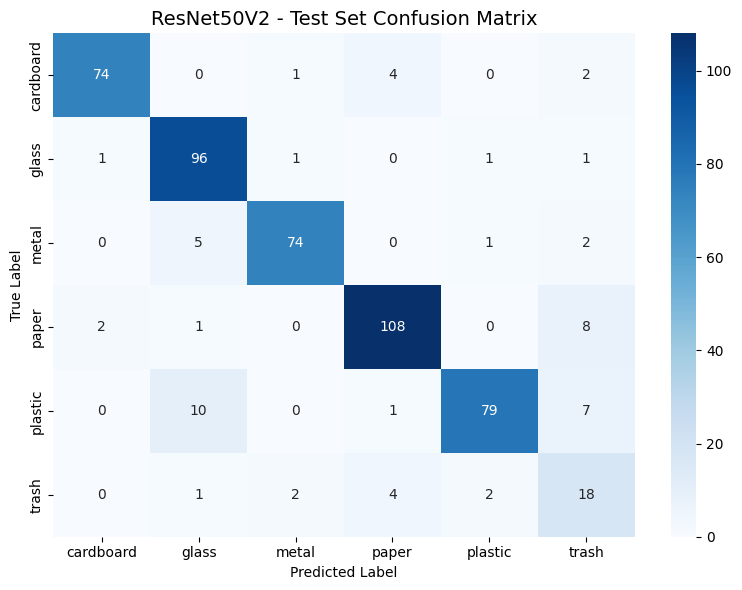


ResNet50V2 - Correct: 449/506 (88.74%)


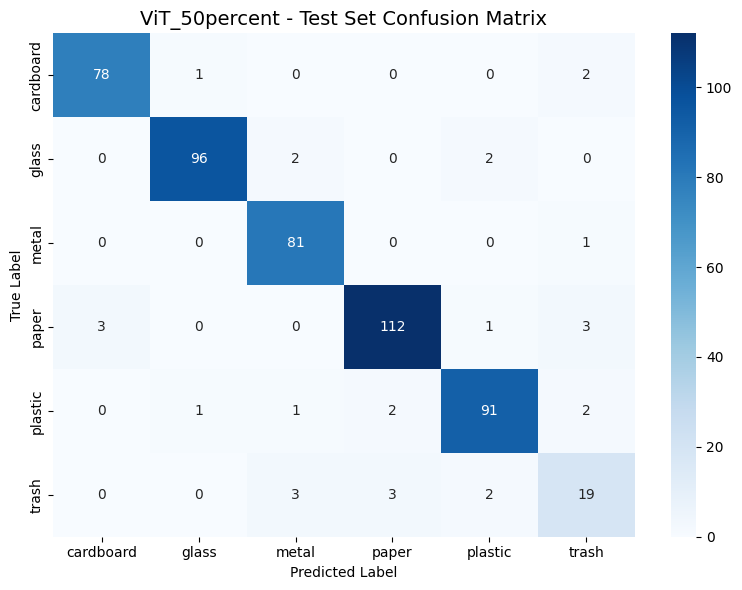


ViT_50percent - Correct: 477/506 (94.27%)


In [27]:
print("\n" + "="*60)
print("CONFUSION MATRICES - ALL MODELS")
print("="*60)

def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{model_name} - Test Set Confusion Matrix', fontsize=14)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'{model_name.lower()}_confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Print summary statistics
    total = np.sum(cm)
    correct = np.trace(cm)
    accuracy = correct / total
    print(f"\n{model_name} - Correct: {correct}/{total} ({accuracy:.2%})")

    return cm

mobilenet_cm = plot_confusion_matrix(mobilenet_test['y_true'], mobilenet_test['y_pred'], "MobileNetV2")
resnet_cm = plot_confusion_matrix(resnet_test['y_true'], resnet_test['y_pred'], "ResNet50V2")
vit_cm = plot_confusion_matrix(vit_test['y_true'], vit_test['y_pred'], "ViT_50percent")

In [ ]:
print("\n" + "="*60)
print("STEP: CONFUSION MATRIX ANALYSIS")
print("="*60)

# Define class indices
class_indices = {name: idx for idx, name in enumerate(class_names)}

def analyze_confusions(y_true, y_pred, model_name):
    """Analyze specific confusions between classes."""
    cm = confusion_matrix(y_true, y_pred)

    # Define confusion pairs
    confusion_pairs = [
        ('paper', 'cardboard'),
        ('cardboard', 'paper'),
        ('glass', 'plastic'),
        ('plastic', 'glass'),
        ('metal', 'trash'),
        ('trash', 'metal')
    ]

    print(f"\n{model_name} - Confusion Analysis:")
    print("-" * 40)

    for class_a, class_b in confusion_pairs:
        idx_a = class_indices[class_a]
        idx_b = class_indices[class_b]
        count = cm[idx_a][idx_b]
        if count > 0:
            print(f"  {class_a} -> {class_b}: {count} images")

    return cm

# Analyze confusion matrices
mobilenet_cm_analysis = analyze_confusions(
    mobilenet_test['y_true'],
    mobilenet_test['y_pred'],
    "MobileNetV2"
)

resnet_cm_analysis = analyze_confusions(
    resnet_test['y_true'],
    resnet_test['y_pred'],
    "ResNet50V2"
)

vit_cm_analysis = analyze_confusions(
    vit_test['y_true'],
    vit_test['y_pred'],
    "ViT (50% Unfreeze)"
)

# Confusion matrix summary table
print("\n" + "="*60)
print("CONFUSION MATRIX SUMMARY")
print("="*60)

summary_data = []
for model_name, cm in [("MobileNetV2", mobilenet_cm_analysis),
                        ("ResNet50V2", resnet_cm_analysis),
                        ("ViT", vit_cm_analysis)]:
    paper_cardboard = cm[class_indices['paper']][class_indices['cardboard']] + cm[class_indices['cardboard']][class_indices['paper']]
    glass_plastic = cm[class_indices['glass']][class_indices['plastic']] + cm[class_indices['plastic']][class_indices['glass']]
    metal_trash = cm[class_indices['metal']][class_indices['trash']] + cm[class_indices['trash']][class_indices['metal']]

    summary_data.append({
        'Model': model_name,
        'Paper/Cardboard': paper_cardboard,
        'Glass/Plastic': glass_plastic,
        'Metal/Trash': metal_trash
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))
summary_df.to_csv('confusion_analysis_summary.csv', index=False)
print("\nConfusion analysis saved to 'confusion_analysis_summary.csv'")


STEP: CONFUSION MATRIX ANALYSIS

MobileNetV2 - Confusion Analysis:
----------------------------------------
  paper -> cardboard: 2 images
  cardboard -> paper: 8 images
  glass -> plastic: 7 images
  plastic -> glass: 10 images
  metal -> trash: 1 images
  trash -> metal: 1 images

ResNet50V2 - Confusion Analysis:
----------------------------------------
  paper -> cardboard: 2 images
  cardboard -> paper: 4 images
  glass -> plastic: 10 images
  plastic -> glass: 6 images
  metal -> trash: 2 images
  trash -> metal: 1 images

ViT (50% Unfreeze) - Confusion Analysis:
----------------------------------------
  paper -> cardboard: 3 images
  cardboard -> paper: 4 images
  glass -> plastic: 4 images
  plastic -> glass: 2 images
  metal -> trash: 1 images
  trash -> metal: 1 images

CONFUSION MATRIX SUMMARY
      Model  Paper/Cardboard  Glass/Plastic  Metal/Trash
MobileNetV2               10             17            2
 ResNet50V2                6             16            3
        ViT 

In [ ]:
print("\n" + "="*60)
print("SUMMARY - FULL PIPELINE")
print("="*60)

# print("\n PHASE 1 - 5-Fold Cross-Validation Results:")
# print(results_df.to_string(index=False))

print("\n PHASE 2 - Final Test Results:")
print(comparison_df.to_string(index=False))

print("\n BEST MODEL: ViT (50% Unfreeze)")
print(f"   Test Accuracy: {vit_test['accuracy']:.4f}")
print(f"   Test Macro F1: {vit_test['macro_f1']:.4f}")

print("\n All files saved:")
print("   - phase1_cv_results.csv")
print("   - phase1_raw_results.pkl")
print("   - mobilenet_final_model.keras")
print("   - resnet_final_model.keras")
print("   - vit_final_50percent.keras")
print("   - final_test_results.pkl")
print("   - final_comparison_results.csv")
print("   - *_confusion_matrix.png")


SUMMARY - FULL PIPELINE

 PHASE 2 - Final Test Results:
             Model Macro F1 Accuracy
       MobileNetV2   0.8318   0.8538
        ResNet50V2   0.8373   0.8577
ViT (50% Unfreeze)   0.8882   0.9150

 BEST MODEL: ViT (50% Unfreeze)
   Test Accuracy: 0.9150
   Test Macro F1: 0.8882

 All files saved:
   - phase1_cv_results.csv
   - phase1_raw_results.pkl
   - mobilenet_final_model.keras
   - resnet_final_model.keras
   - vit_final_50percent.keras
   - final_test_results.pkl
   - final_comparison_results.csv
   - *_confusion_matrix.png


In [ ]:
print("\n" + "="*60)
print("McNEMAR'S TEST - STATISTICAL VALIDATION")
print("="*60)

!pip install -q statsmodels

import numpy as np
from statsmodels.stats.contingency_tables import mcnemar

print("\n" + "-"*40)
print("Extracting predictions from test results...")
print("-"*40)

y_true_test = vit_test['y_true']  # All models used the same test set, so y_true is the same
y_pred_mobilenet_test = mobilenet_test['y_pred']
y_pred_resnet_test = resnet_test['y_pred']
y_pred_vit_test = vit_test['y_pred']

print(f" Test set size: {len(y_true_test)} images")
print(f"   MobileNetV2 predictions: {len(y_pred_mobilenet_test)}")
print(f"   ResNet50V2 predictions: {len(y_pred_resnet_test)}")
print(f"   ViT predictions: {len(y_pred_vit_test)}")

def mcnemar_test(y_true, y_pred1, y_pred2, model1_name, model2_name):

    # Build contingency table
    a = b = c = d = 0  # Both correct, 1 correct 2 wrong, 1 wrong 2 correct, both wrong

    for i in range(len(y_true)):
        m1_correct = (y_pred1[i] == y_true[i])
        m2_correct = (y_pred2[i] == y_true[i])

        if m1_correct and m2_correct:
            a += 1
        elif m1_correct and not m2_correct:
            b += 1
        elif not m1_correct and m2_correct:
            c += 1
        else:
            d += 1

    contingency_table = np.array([[a, b], [c, d]])
    result = mcnemar(contingency_table, exact=False, correction=True)

    print(f"\n{'='*50}")
    print(f"{model1_name} vs {model2_name}")
    print(f"{'='*50}")
    print(f"  Contingency Table:")
    print(f"    Both Correct:                      {a}")
    print(f"    {model1_name} Correct, {model2_name} Wrong: {b}")
    print(f"    {model1_name} Wrong, {model2_name} Correct: {c}")
    print(f"    Both Wrong:                        {d}")
    print(f"\n  McNemar's X²: {result.statistic:.4f}")
    print(f"  P-value:      {result.pvalue:.4f}")

    if result.pvalue < 0.05:
        print(f"\n  {model1_name} is SIGNIFICANTLY different from {model2_name} (p < 0.05)")
    else:
        print(f"\n  No significant difference between models (p ≥ 0.05)")

    return result.pvalue

# Comparison 1: ViT vs ResNet50V2
p_vit_resnet = mcnemar_test(
    y_true_test,
    y_pred_vit_test,
    y_pred_resnet_test,
    "ViT (50% Unfreeze)",
    "ResNet50V2"
)

# Comparison 2: ViT vs MobileNetV2
p_vit_mobilenet = mcnemar_test(
    y_true_test,
    y_pred_vit_test,
    y_pred_mobilenet_test,
    "ViT (50% Unfreeze)",
    "MobileNetV2"
)

# Comparison 3: ResNet50V2 vs MobileNetV2
p_resnet_mobilenet = mcnemar_test(
    y_true_test,
    y_pred_resnet_test,
    y_pred_mobilenet_test,
    "ResNet50V2",
    "MobileNetV2"
)

print("\n" + "="*60)
print("McNEMAR'S TEST SUMMARY")
print("="*60)

print(f"\n{'Comparison':<30} {'P-Value':<12} {'Significant?'}")
print("-"*55)
print(f"{'ViT vs ResNet50V2':<30} {p_vit_resnet:<12.4f} {' Yes' if p_vit_resnet < 0.05 else ' No'}")
print(f"{'ViT vs MobileNetV2':<30} {p_vit_mobilenet:<12.4f} {' Yes' if p_vit_mobilenet < 0.05 else ' No'}")
print(f"{'ResNet50V2 vs MobileNetV2':<30} {p_resnet_mobilenet:<12.4f} {' Yes' if p_resnet_mobilenet < 0.05 else ' No'}")

print("\n" + "="*60)
print("INTERPRETATION")
print("="*60)

if p_vit_resnet < 0.05:
    print(" The Vision Transformer statistically significantly outperforms ResNet50V2 (p < 0.05)")
else:
    print(" No statistically significant difference was found between ViT and ResNet50V2")

if p_vit_mobilenet < 0.05:
    print(" The Vision Transformer statistically significantly outperforms MobileNetV2 (p < 0.05)")
else:
    print(" No statistically significant difference was found between ViT and MobileNetV2")

if p_resnet_mobilenet < 0.05:
    print(" ResNet50V2 statistically significantly outperforms MobileNetV2 (p < 0.05)")
else:
    print(" No statistically significant difference was found between ResNet50V2 and MobileNetV2")


McNEMAR'S TEST - STATISTICAL VALIDATION

----------------------------------------
Extracting predictions from test results...
----------------------------------------
 Test set size: 506 images
   MobileNetV2 predictions: 506
   ResNet50V2 predictions: 506
   ViT predictions: 506

ViT (50% Unfreeze) vs ResNet50V2
  Contingency Table:
    Both Correct:                      416
    ViT (50% Unfreeze) Correct, ResNet50V2 Wrong: 47
    ViT (50% Unfreeze) Wrong, ResNet50V2 Correct: 18
    Both Wrong:                        25

  McNemar's X²: 12.0615
  P-value:      0.0005

  ViT (50% Unfreeze) is SIGNIFICANTLY different from ResNet50V2 (p < 0.05)

ViT (50% Unfreeze) vs MobileNetV2
  Contingency Table:
    Both Correct:                      414
    ViT (50% Unfreeze) Correct, MobileNetV2 Wrong: 49
    ViT (50% Unfreeze) Wrong, MobileNetV2 Correct: 18
    Both Wrong:                        25

  McNemar's X²: 13.4328
  P-value:      0.0002

  ViT (50% Unfreeze) is SIGNIFICANTLY different fr

In [ ]:
print("\n" + "="*60)
print("STEP: LOADING MODELS FOR XAI")
print("="*60)

import tensorflow as tf
import pickle
import os
import cv2
import numpy as np

# Load ResNet50V2
try:
    resnet_model = tf.keras.models.load_model('resnet_final_model.keras')
    print("ResNet50V2 loaded from 'resnet_final_model.keras'")
except Exception as e:
    print(f"ResNet50V2 load failed: {e}")
    resnet_model = None

# Load MobileNetV2
try:
    mobilenet_model = tf.keras.models.load_model('mobilenet_final_model.keras')
    print("MobileNetV2 loaded from 'mobilenet_final_model.keras'")
except Exception as e:
    print(f"MobileNetV2 load failed: {e}")
    mobilenet_model = None

# Load ViT - try memory first, then file
vit_model = None
try:
    # Try memory first
    if 'vit_model_phase2' in dir():
        vit_model = vit_model_phase2
        print("ViT loaded from memory (vit_model_phase2)")
    elif 'vit_final' in dir():
        vit_model = vit_final
        print("ViT loaded from memory (vit_final)")
    else:
        vit_model = tf.keras.models.load_model('vit_final_50percent.keras')
        print("ViT loaded from 'vit_final_50percent.keras'")
except Exception as e:
    print(f"ViT load failed: {e}")
    vit_model = None

# Check if models loaded
if resnet_model is not None and mobilenet_model is not None and vit_model is not None:
    print("\nAll models loaded successfully!")
else:
    print("\nWarning: Some models failed to load. XAI may not work correctly.")

# Load test set
try:
    with open('test_set_isolated.pkl', 'rb') as f:
        test_data = pickle.load(f)
    test_paths = test_data['paths']
    test_labels = test_data['labels']
    class_names = test_data['class_names']
    print(f"Test set loaded: {len(test_paths)} images")
except Exception as e:
    print(f"Test set load failed: {e}")


STEP: LOADING MODELS FOR XAI
ResNet50V2 loaded from 'resnet_final_model.keras'
MobileNetV2 loaded from 'mobilenet_final_model.keras'
ViT loaded from memory (vit_model_phase2)

All models loaded successfully!
Test set loaded: 506 images


In [ ]:
print("\n" + "="*60)
print("STEP: ViT ATTENTION MAP EXTRACTION")
print("="*60)

import cv2
from matplotlib import cm
import warnings
warnings.filterwarnings('ignore')

def extract_vit_attention(model, image, layer_idx=-1):
    # Ensure image has batch dimension
    if len(image.shape) == 3:
        image = np.expand_dims(image, axis=0)

    # Find the transformer block
    if layer_idx == -1:
        # Find the last transformer block
        block_layers = [l for l in model.layers if l.name.startswith("block_")]
        if block_layers:
            target_layer = block_layers[-1]
        else:
            raise ValueError("No transformer blocks found in model")
    else:
        target_layer = model.get_layer(f"block_{layer_idx}")

    # Use Grad-CAM style on the transformer output
    with tf.GradientTape() as tape:
        # Get the output of the last transformer block
        grad_model = keras.Model(
            inputs=model.input,
            outputs=[model.get_layer(target_layer.name).output, model.output]
        )
        conv_outputs, predictions = grad_model(image)
        class_idx = np.argmax(predictions[0])
        loss = predictions[0][class_idx]

    # Compute gradients
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1))

    # Weight the feature maps
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_outputs), axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = heatmap.numpy()

    # Resize to image size (224x224)
    attention_map = cv2.resize(heatmap, (224, 224))

    return attention_map

def overlay_heatmap(image, heatmap, alpha=0.6):
    # Normalize heatmap to [0, 1]
    heatmap = (heatmap - np.min(heatmap)) / (np.max(heatmap) - np.min(heatmap) + 1e-8)

    # Apply colormap (jet)
    heatmap_colored = cm.jet(heatmap)[:, :, :3]

    # Overlay on image
    overlayed = (1 - alpha) * image + alpha * heatmap_colored
    overlayed = np.clip(overlayed, 0, 1)

    return overlayed

print(" ViT attention extraction ready")


STEP: ViT ATTENTION MAP EXTRACTION
 ViT attention extraction ready


In [ ]:
print("\n" + "="*60)
print("STEP: CNN GRAD-CAM")
print("="*60)

def get_grad_cam(model, image, class_idx, last_conv_layer_name):
    # Ensure image has batch dimension
    if len(image.shape) == 3:
        image = np.expand_dims(image, axis=0)

    # Create gradient model
    grad_model = keras.Model(
        inputs=model.input,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Compute gradients
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image)
        loss = predictions[:, class_idx]

    # Get gradients
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight feature maps
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_outputs), axis=-1)

    # Normalize
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = heatmap.numpy()

    # Resize to image size (224x224)
    heatmap = cv2.resize(heatmap, (224, 224))

    return heatmap

def get_last_conv_layer(model):
    """Find the last convolutional layer in a model."""
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    raise ValueError("No Conv2D layer found in model")

print("Grad-CAM functions ready")


STEP: CNN GRAD-CAM
Grad-CAM functions ready


In [ ]:
print("\n" + "="*60)
print("STEP: FINDING LAST CONV LAYERS")
print("="*60)

# Use the loaded models (resnet_model and mobilenet_model)

# Find last conv layers
try:
    resnet_last_conv = get_last_conv_layer(resnet_model)
    print(f"ResNet50V2 last conv layer: {resnet_last_conv}")
except Exception as e:
    resnet_last_conv = 'conv5_block3_3_conv'
    print(f"ResNet50V2 last conv layer (fallback): {resnet_last_conv}")

try:
    mobilenet_last_conv = get_last_conv_layer(mobilenet_model)
    print(f"MobileNetV2 last conv layer: {mobilenet_last_conv}")
except Exception as e:
    mobilenet_last_conv = 'Conv_1'
    print(f"MobileNetV2 last conv layer (fallback): {mobilenet_last_conv}")

print("Grad-CAM ready")


STEP: FINDING LAST CONV LAYERS
ResNet50V2 last conv layer (fallback): conv5_block3_3_conv
MobileNetV2 last conv layer (fallback): Conv_1
Grad-CAM ready


In [ ]:
print("\n" + "="*60)
print("STEP: SELECTING TEST IMAGES FOR XAI")
print("="*60)

import random
random.seed(42)

# Load test set
with open('test_set_isolated.pkl', 'rb') as f:
    test_data = pickle.load(f)

test_paths = test_data['paths']
test_labels = test_data['labels']

# Select 2 images per class (or all if less than 2)
selected_indices = []
for class_idx in range(NUM_CLASSES):
    class_indices = [i for i, label in enumerate(test_labels) if label == class_idx]
    if len(class_indices) >= 2:
        chosen = random.sample(class_indices, 2)
    else:
        chosen = class_indices[:1]
    selected_indices.extend(chosen)

print(f"Selected {len(selected_indices)} images for XAI")

# Get image paths and load images
selected_paths = [test_paths[i] for i in selected_indices]
selected_labels = [test_labels[i] for i in selected_indices]

selected_images = []
for path in selected_paths:
    full_path = os.path.join(DATA_DIR, path)
    img = cv2.imread(full_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    img = img / 255.0
    selected_images.append(img)

print(f"Loaded {len(selected_images)} images for XAI")


STEP: SELECTING TEST IMAGES FOR XAI
Selected 12 images for XAI
Loaded 12 images for XAI


In [ ]:
print("\n" + "="*60)
print("STEP: GRAD-CAM USING BASE MODELS DIRECTLY")
print("="*60)

import cv2
import numpy as np
import tensorflow as tf
from tensorflow import keras
from matplotlib import cm

def get_grad_cam_from_base(base_model, image, class_idx, last_conv_name):
    """
    Generate Grad-CAM directly from the base model.
    This bypasses the Sequential wrapper issue.
    """
    # Ensure image has batch dimension
    if len(image.shape) == 3:
        image = np.expand_dims(image, axis=0)

    # Find the last Conv2D layer in the base model
    target_layer = None
    for layer in reversed(base_model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            target_layer = layer
            break

    if target_layer is None:
        raise ValueError("No Conv2D layer found in base model")

    print(f"  Using layer: {target_layer.name}")

    # Build the gradient model using the base model
    grad_model = keras.Model(
        inputs=base_model.input,
        outputs=[target_layer.output, base_model.output]
    )

    # Compute gradients
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image)
        loss = predictions[:, class_idx]

    # Get gradients
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight feature maps
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_outputs), axis=-1)

    # Normalize
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = heatmap.numpy()

    # Resize to image size
    heatmap = cv2.resize(heatmap, (224, 224))

    return heatmap

def extract_base_model(sequential_model):
    """
    Extract the base model from a Sequential model.
    """
    for layer in sequential_model.layers:
        if hasattr(layer, 'layers') and not isinstance(layer, tf.keras.layers.Dropout):
            # This is likely the base model (ResNet50V2 or MobileNetV2)
            if hasattr(layer, 'input') and hasattr(layer, 'output'):
                return layer
    return None

# Extract base models
resnet_base = extract_base_model(resnet_model)
mobilenet_base = extract_base_model(mobilenet_model)

print(f"ResNet50V2 base model extracted: {resnet_base is not None}")
print(f"MobileNetV2 base model extracted: {mobilenet_base is not None}")

if resnet_base is not None:
    print(f"ResNet50V2 base model name: {resnet_base.name}")
    # Build the base model
    dummy_input = np.random.randn(1, 224, 224, 3).astype(np.float32)
    _ = resnet_base(dummy_input)
    print("ResNet50V2 base model built")

if mobilenet_base is not None:
    print(f"MobileNetV2 base model name: {mobilenet_base.name}")
    # Build the base model
    dummy_input = np.random.randn(1, 224, 224, 3).astype(np.float32)
    _ = mobilenet_base(dummy_input)
    print("MobileNetV2 base model built")

# Last conv layer names for base models
resnet_last_conv = None
mobilenet_last_conv = None

if resnet_base is not None:
    for layer in reversed(resnet_base.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            resnet_last_conv = layer.name
            break

if mobilenet_base is not None:
    for layer in reversed(mobilenet_base.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            mobilenet_last_conv = layer.name
            break

print(f"ResNet50V2 last conv layer: {resnet_last_conv}")
print(f"MobileNetV2 last conv layer: {mobilenet_last_conv}")

# Test Grad-CAM
print("\n" + "="*60)
print("Testing Grad-CAM on base models...")
print("="*60)

test_img = selected_images[0]
img_input = np.expand_dims(test_img, axis=0)
pred = vit_model.predict(img_input, verbose=0)
pred_class = np.argmax(pred)

print(f"Test image predicted class: {class_names[pred_class]}")

if resnet_base is not None and resnet_last_conv is not None:
    try:
        grad_cam_resnet = get_grad_cam_from_base(
            resnet_base, test_img, pred_class, resnet_last_conv
        )
        print("ResNet50V2 Grad-CAM successful!")
    except Exception as e:
        print(f"ResNet50V2 Grad-CAM failed: {e}")
else:
    print("ResNet50V2 base model not available")

if mobilenet_base is not None and mobilenet_last_conv is not None:
    try:
        grad_cam_mobilenet = get_grad_cam_from_base(
            mobilenet_base, test_img, pred_class, mobilenet_last_conv
        )
        print("MobileNetV2 Grad-CAM successful!")
    except Exception as e:
        print(f"MobileNetV2 Grad-CAM failed: {e}")
else:
    print("MobileNetV2 base model not available")


STEP: GRAD-CAM USING BASE MODELS DIRECTLY
ResNet50V2 base model extracted: True
MobileNetV2 base model extracted: True
ResNet50V2 base model name: resnet50v2
ResNet50V2 base model built
MobileNetV2 base model name: mobilenetv2_1.00_224
MobileNetV2 base model built
ResNet50V2 last conv layer: conv5_block3_3_conv
MobileNetV2 last conv layer: Conv_1

Testing Grad-CAM on base models...
Test image predicted class: cardboard
  Using layer: conv5_block3_3_conv
ResNet50V2 Grad-CAM successful!
  Using layer: Conv_1
MobileNetV2 Grad-CAM successful!


In [ ]:
print("\n" + "="*60)
print("STEP: GENERATING FULL XAI VISUALIZATIONS")
print("="*60)

def get_grad_cam_from_base(base_model, image, class_idx):
    """Generate Grad-CAM directly from the base model."""
    if len(image.shape) == 3:
        image = np.expand_dims(image, axis=0)

    # Find the last Conv2D layer in the base model
    target_layer = None
    for layer in reversed(base_model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            target_layer = layer
            break

    if target_layer is None:
        raise ValueError("No Conv2D layer found")

    # Build the gradient model
    grad_model = keras.Model(
        inputs=base_model.input,
        outputs=[target_layer.output, base_model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image)
        loss = predictions[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_outputs), axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = heatmap.numpy()
    heatmap = cv2.resize(heatmap, (224, 224))

    return heatmap

# Generate visualizations for all images
attention_maps = []
grad_cams_resnet = []
grad_cams_mobilenet = []
predictions = []

for i, img in enumerate(selected_images):
    print(f"  Image {i+1}/{len(selected_images)}...")

    img_input = np.expand_dims(img, axis=0)
    pred = vit_model.predict(img_input, verbose=0)
    pred_class = np.argmax(pred)
    predictions.append(pred_class)

    # ViT Attention
    try:
        attn_map = extract_vit_attention(vit_model, img)
        attention_maps.append(attn_map)
    except Exception as e:
        print(f"    ViT attention failed: {e}")
        attention_maps.append(None)

    # ResNet Grad-CAM
    try:
        grad_cam_resnet = get_grad_cam_from_base(resnet_base, img, pred_class)
        grad_cams_resnet.append(grad_cam_resnet)
    except Exception as e:
        print(f"    ResNet Grad-CAM failed: {e}")
        grad_cams_resnet.append(None)

    # MobileNet Grad-CAM
    try:
        grad_cam_mobilenet = get_grad_cam_from_base(mobilenet_base, img, pred_class)
        grad_cams_mobilenet.append(grad_cam_mobilenet)
    except Exception as e:
        print(f"    MobileNet Grad-CAM failed: {e}")
        grad_cams_mobilenet.append(None)

print("\nVisualization generation complete")

vit_success = len([a for a in attention_maps if a is not None])
resnet_success = len([g for g in grad_cams_resnet if g is not None])
mobilenet_success = len([g for g in grad_cams_mobilenet if g is not None])

print(f"ViT Attention maps: {vit_success}/{len(selected_images)}")
print(f"ResNet Grad-CAM: {resnet_success}/{len(selected_images)}")
print(f"MobileNet Grad-CAM: {mobilenet_success}/{len(selected_images)}")


STEP: GENERATING FULL XAI VISUALIZATIONS
  Image 1/12...
  Image 2/12...
  Image 3/12...
  Image 4/12...
  Image 5/12...
  Image 6/12...
  Image 7/12...
  Image 8/12...
  Image 9/12...
  Image 10/12...
  Image 11/12...
  Image 12/12...

Visualization generation complete
ViT Attention maps: 12/12
ResNet Grad-CAM: 12/12
MobileNet Grad-CAM: 12/12



STEP: HEATMAP GALLERY


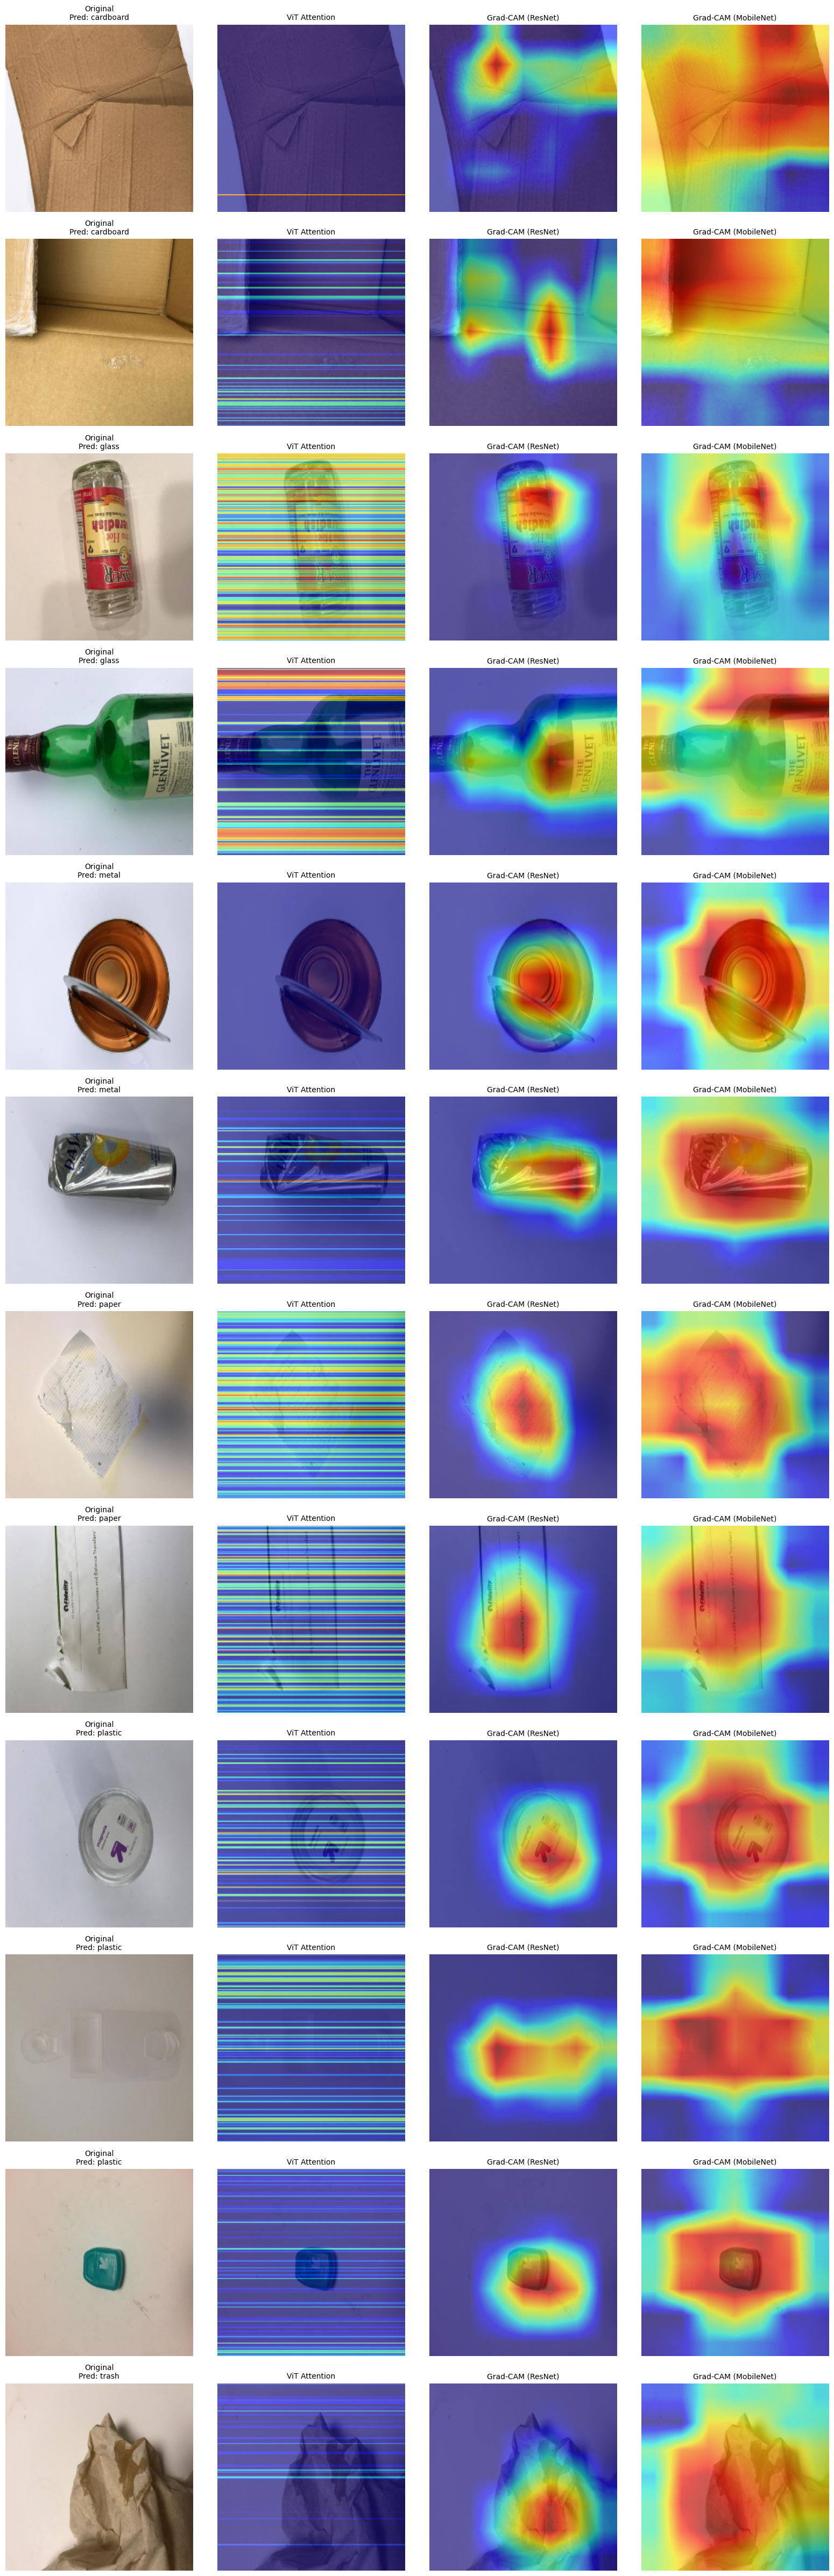

Heatmap gallery saved as 'heatmap_gallery.png'


In [ ]:
print("\n" + "="*60)
print("STEP: HEATMAP GALLERY")
print("="*60)

def overlay_heatmap(image, heatmap, alpha=0.6):
    heatmap = (heatmap - np.min(heatmap)) / (np.max(heatmap) - np.min(heatmap) + 1e-8)
    heatmap_colored = cm.jet(heatmap)[:, :, :3]
    overlayed = (1 - alpha) * image + alpha * heatmap_colored
    overlayed = np.clip(overlayed, 0, 1)
    return overlayed

n_images = len(selected_images)
fig, axes = plt.subplots(n_images, 4, figsize=(16, 4 * n_images))

if n_images == 1:
    axes = axes.reshape(1, -1)

for i in range(n_images):
    # Original image
    axes[i, 0].imshow(selected_images[i])
    axes[i, 0].set_title(f'Original\nPred: {class_names[predictions[i]]}', fontsize=10)
    axes[i, 0].axis('off')

    # ViT Attention
    if attention_maps[i] is not None:
        overlay = overlay_heatmap(selected_images[i], attention_maps[i])
        axes[i, 1].imshow(overlay)
        axes[i, 1].set_title('ViT Attention', fontsize=10)
        axes[i, 1].axis('off')
    else:
        axes[i, 1].text(0.5, 0.5, 'N/A', ha='center', va='center')
        axes[i, 1].axis('off')

    # Grad-CAM ResNet
    if grad_cams_resnet[i] is not None:
        overlay = overlay_heatmap(selected_images[i], grad_cams_resnet[i])
        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title('Grad-CAM (ResNet)', fontsize=10)
        axes[i, 2].axis('off')
    else:
        axes[i, 2].text(0.5, 0.5, 'N/A', ha='center', va='center')
        axes[i, 2].axis('off')

    # Grad-CAM MobileNet
    if grad_cams_mobilenet[i] is not None:
        overlay = overlay_heatmap(selected_images[i], grad_cams_mobilenet[i])
        axes[i, 3].imshow(overlay)
        axes[i, 3].set_title('Grad-CAM (MobileNet)', fontsize=10)
        axes[i, 3].axis('off')
    else:
        axes[i, 3].text(0.5, 0.5, 'N/A', ha='center', va='center')
        axes[i, 3].axis('off')

plt.tight_layout()
plt.savefig('heatmap_gallery.png', dpi=300, bbox_inches='tight')
plt.show()
print("Heatmap gallery saved as 'heatmap_gallery.png'")


STEP: INDIVIDUAL IMAGE ANALYSIS

Image 1: True=cardboard, Pred=cardboard


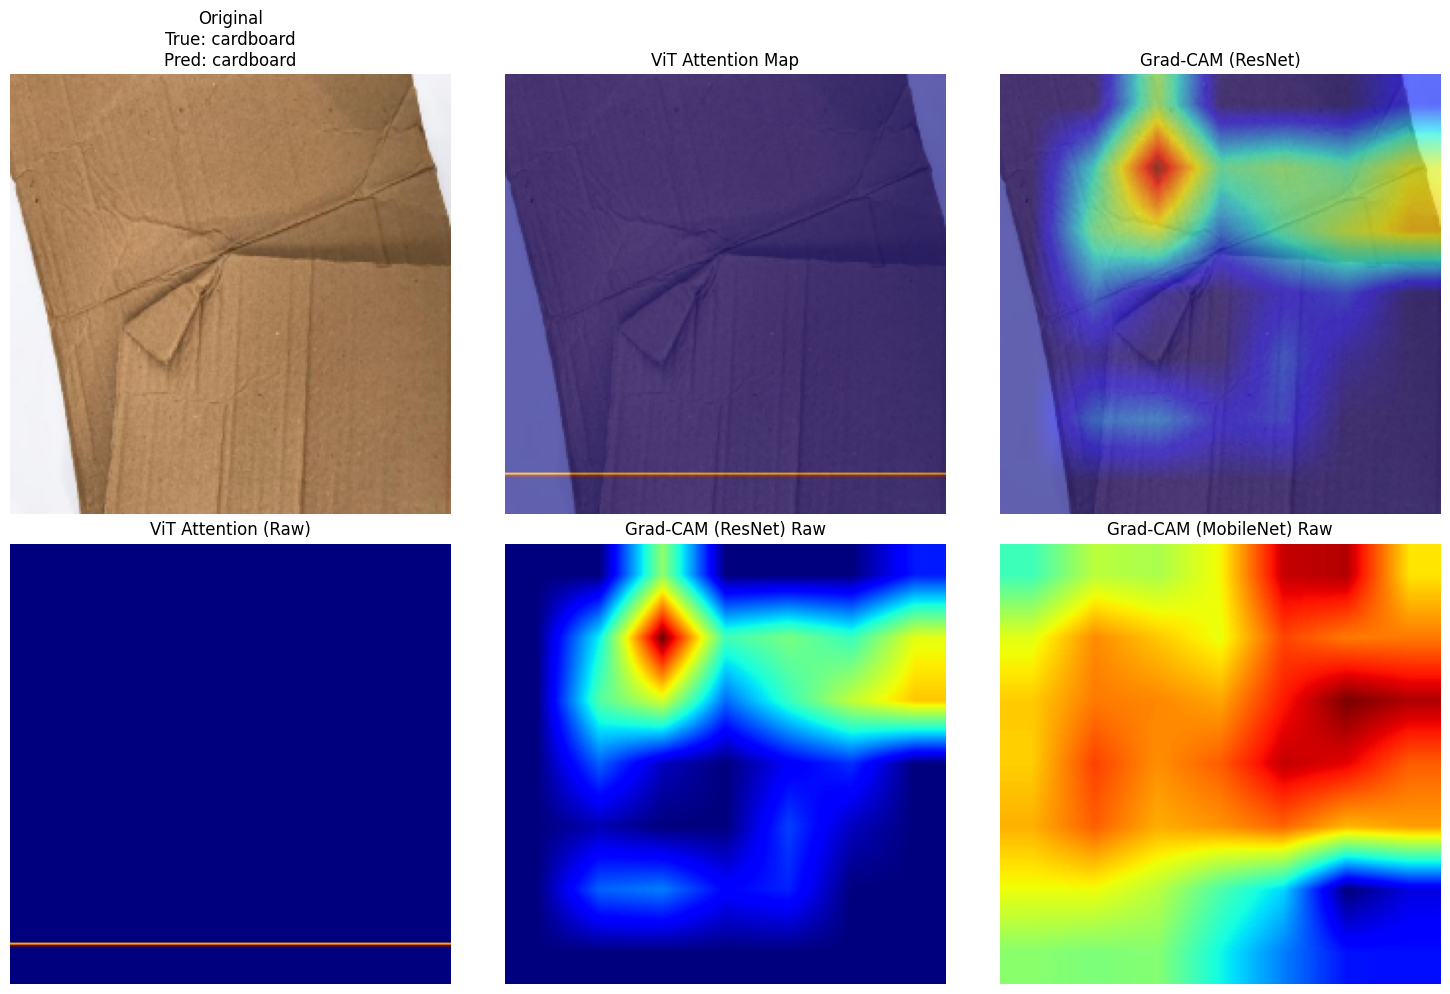


Image 2: True=cardboard, Pred=cardboard


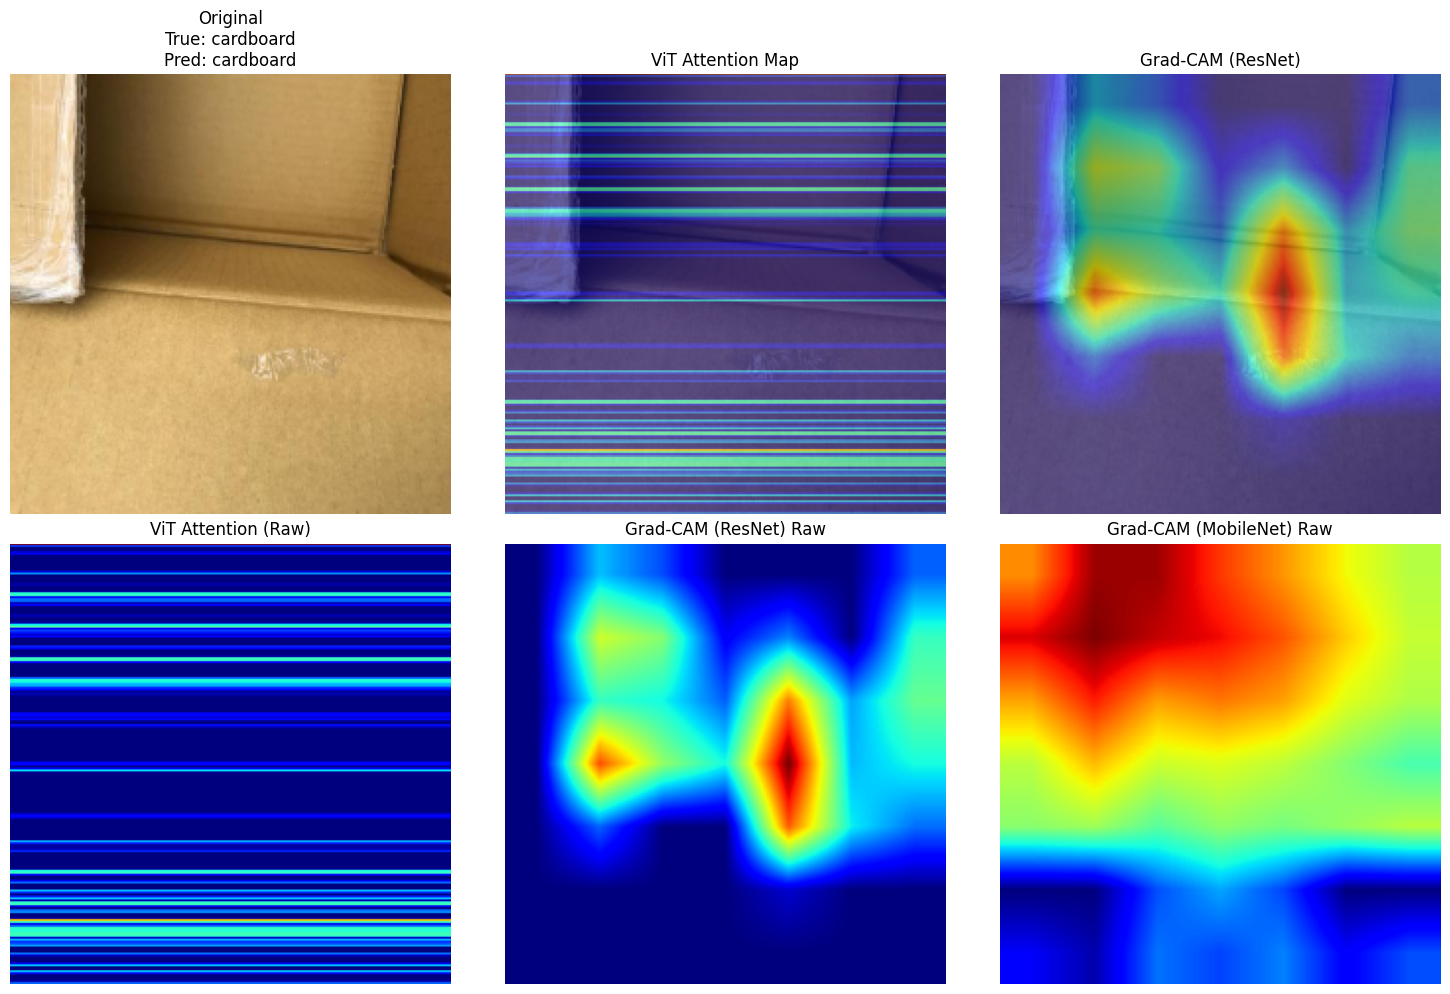


Image 3: True=glass, Pred=glass


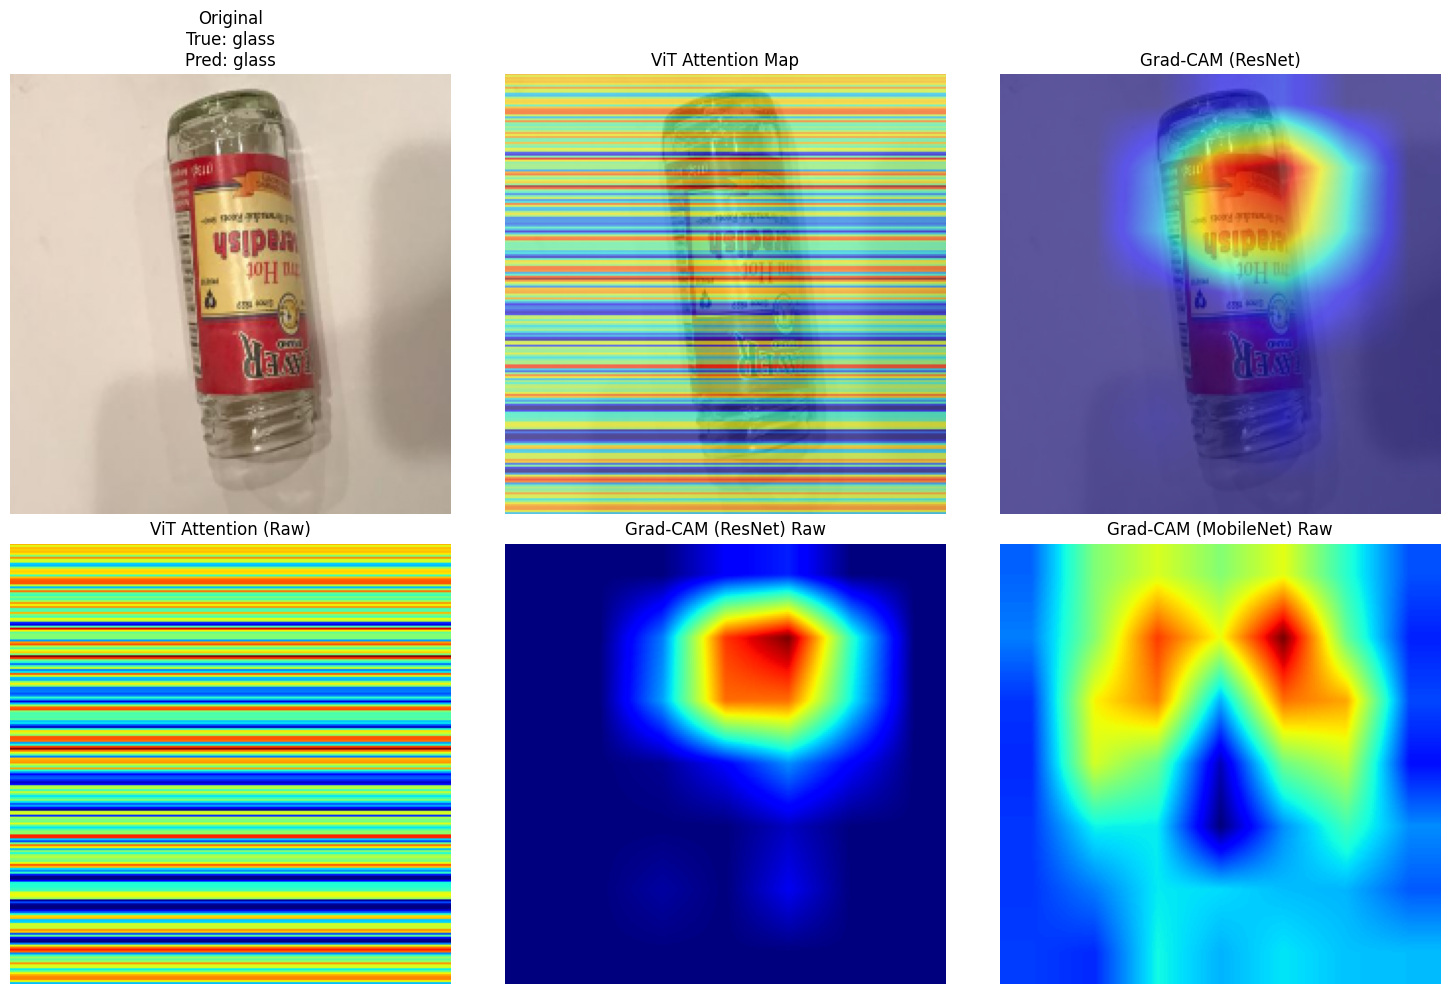

In [ ]:
print("\n" + "="*60)
print("STEP: INDIVIDUAL IMAGE ANALYSIS")
print("="*60)

def analyze_image(img, true_label, pred_class, attn_map, grad_cam_resnet, grad_cam_mobilenet):
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Original image
    axes[0, 0].imshow(img)
    axes[0, 0].set_title(f'Original\nTrue: {class_names[true_label]}\nPred: {class_names[pred_class]}', fontsize=12)
    axes[0, 0].axis('off')

    # ViT Attention
    if attn_map is not None:
        overlay = overlay_heatmap(img, attn_map)
        axes[0, 1].imshow(overlay)
        axes[0, 1].set_title('ViT Attention Map', fontsize=12)
        axes[0, 1].axis('off')
    else:
        axes[0, 1].text(0.5, 0.5, 'N/A', ha='center', va='center')
        axes[0, 1].axis('off')

    # Grad-CAM ResNet
    if grad_cam_resnet is not None:
        overlay = overlay_heatmap(img, grad_cam_resnet)
        axes[0, 2].imshow(overlay)
        axes[0, 2].set_title('Grad-CAM (ResNet)', fontsize=12)
        axes[0, 2].axis('off')
    else:
        axes[0, 2].text(0.5, 0.5, 'N/A', ha='center', va='center')
        axes[0, 2].axis('off')

    # Raw heatmaps
    if attn_map is not None:
        axes[1, 0].imshow(attn_map, cmap='jet')
        axes[1, 0].set_title('ViT Attention (Raw)', fontsize=12)
        axes[1, 0].axis('off')
    else:
        axes[1, 0].text(0.5, 0.5, 'N/A', ha='center', va='center')
        axes[1, 0].axis('off')

    if grad_cam_resnet is not None:
        axes[1, 1].imshow(grad_cam_resnet, cmap='jet')
        axes[1, 1].set_title('Grad-CAM (ResNet) Raw', fontsize=12)
        axes[1, 1].axis('off')
    else:
        axes[1, 1].text(0.5, 0.5, 'N/A', ha='center', va='center')
        axes[1, 1].axis('off')

    if grad_cam_mobilenet is not None:
        axes[1, 2].imshow(grad_cam_mobilenet, cmap='jet')
        axes[1, 2].set_title('Grad-CAM (MobileNet) Raw', fontsize=12)
        axes[1, 2].axis('off')
    else:
        axes[1, 2].text(0.5, 0.5, 'N/A', ha='center', va='center')
        axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()

# Analyze first 3 images
for i in range(min(3, len(selected_images))):
    print(f"\n{'='*60}")
    print(f"Image {i+1}: True={class_names[selected_labels[i]]}, Pred={class_names[predictions[i]]}")
    print('='*60)
    analyze_image(
        selected_images[i],
        selected_labels[i],
        predictions[i],
        attention_maps[i] if i < len(attention_maps) else None,
        grad_cams_resnet[i] if i < len(grad_cams_resnet) else None,
        grad_cams_mobilenet[i] if i < len(grad_cams_mobilenet) else None
    )

In [ ]:
print("\n" + "="*60)
print("STEP: MISCLASSIFICATION ANALYSIS")
print("="*60)

def find_misclassifications(model_name, y_true, y_pred, test_paths, test_labels, max_samples=3):
    """Find and display misclassified examples."""
    misclassified_indices = []
    for i in range(len(y_true)):
        if y_true[i] != y_pred[i]:
            misclassified_indices.append(i)

    print(f"\n{model_name} - Misclassified Samples: {len(misclassified_indices)}/{len(y_true)}")

    if len(misclassified_indices) == 0:
        print("  No misclassifications found!")
        return

    # Get class indices for specific categories
    class_indices = {name: idx for idx, name in enumerate(class_names)}

    # Categorize misclassifications
    categories = {
        'Paper/Cardboard': [],
        'Glass/Plastic': [],
        'Metal/Trash': [],
        'Other': []
    }

    for idx in misclassified_indices:
        true_class = y_true[idx]
        pred_class = y_pred[idx]
        true_name = class_names[true_class]
        pred_name = class_names[pred_class]

        if (true_name == 'paper' and pred_name == 'cardboard') or (true_name == 'cardboard' and pred_name == 'paper'):
            categories['Paper/Cardboard'].append(idx)
        elif (true_name == 'glass' and pred_name == 'plastic') or (true_name == 'plastic' and pred_name == 'glass'):
            categories['Glass/Plastic'].append(idx)
        elif (true_name == 'metal' and pred_name == 'trash') or (true_name == 'trash' and pred_name == 'metal'):
            categories['Metal/Trash'].append(idx)
        else:
            categories['Other'].append(idx)

    # Display samples
    print("\n  Misclassification Examples:")
    for category, indices in categories.items():
        if indices and len(indices) > 0:
            print(f"\n    {category}: {len(indices)} samples")
            for idx in indices[:max_samples]:
                true_name = class_names[y_true[idx]]
                pred_name = class_names[y_pred[idx]]
                print(f"      Image {idx}: True={true_name}, Pred={pred_name}")

# Run misclassification analysis
find_misclassifications("MobileNetV2", mobilenet_test['y_true'], mobilenet_test['y_pred'], test_paths, test_labels)
find_misclassifications("ResNet50V2", resnet_test['y_true'], resnet_test['y_pred'], test_paths, test_labels)
find_misclassifications("ViT", vit_test['y_true'], vit_test['y_pred'], test_paths, test_labels)


STEP: MISCLASSIFICATION ANALYSIS

MobileNetV2 - Misclassified Samples: 74/506

  Misclassification Examples:

    Paper/Cardboard: 10 samples
      Image 25: True=cardboard, Pred=paper
      Image 79: True=cardboard, Pred=paper
      Image 108: True=cardboard, Pred=paper

    Glass/Plastic: 17 samples
      Image 16: True=glass, Pred=plastic
      Image 17: True=plastic, Pred=glass
      Image 35: True=glass, Pred=plastic

    Metal/Trash: 2 samples
      Image 325: True=trash, Pred=metal
      Image 447: True=metal, Pred=trash

    Other: 45 samples
      Image 67: True=plastic, Pred=metal
      Image 69: True=trash, Pred=paper
      Image 71: True=glass, Pred=metal

ResNet50V2 - Misclassified Samples: 72/506

  Misclassification Examples:

    Paper/Cardboard: 6 samples
      Image 167: True=cardboard, Pred=paper
      Image 213: True=paper, Pred=cardboard
      Image 216: True=cardboard, Pred=paper

    Glass/Plastic: 16 samples
      Image 24: True=glass, Pred=plastic
      Image 